<div style="background: linear-gradient(135deg, #1e293b 0%, #0f172a 100%); padding: 30px; border-radius: 8px; margin-bottom: 25px; box-shadow: 0 4px 6px -1px rgba(0, 0, 0, 0.1);">
    <h1 style="color: #f8fafc; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-weight: 700; margin: 0; font-size: 2.2em; letter-spacing: -0.5px;"> Factores esfuerzo Alumnos PISA 2012-2022 🌍
</h1>
    <p style="color: #94a3b8; font-family: 'Segoe UI', sans-serif; margin: 8px 0 0 0; font-size: 1.1em;"> Estudio del factor 'Deberes' en los informes PISA
 </p>
    
</div>

# 📋 Descripción



Este cuaderno evalúa la **Hipótesis de Eficiencia del Estudio**: *"Asignar más horas de deberes a nivel global no garantiza linealmente mejores resultados en Matemáticas, existiendo un umbral de saturación (curva en U invertida) y una fuerte mediación del apoyo escolar y la autorregulación"*.

El flujo de datos trabaja directamente sobre dos niveles de agregación analítica y de persistencia:
1. **Nivel Colegio (`CNT`, `CNTSCHID`):** Los microdatos de los alumnos se recodifican en memoria a horas continuas y se agregan de forma ponderada (`W_FSTUWT`) a nivel de centro educativo, cruzándose directamente con las características del propio colegio y su nota media en Matemáticas.
2. **Nivel País (`CNT`):** Vista macro agregada a nivel nacional para contrastar la Paradoja de Simpson, segmentar sistemas educativos (*K-Means*) y analizar la evolución longitudinal (2012–2022).

## Selección de variables

**1. Microdatos de Estudiantes (`pisa2022_estudiantes.parquet`)**

| Código de variable | Nombre Semántico | Descripción y tratamiento metodológico |
| :--- | :--- | :--- |
| `ST296Q01JA` | `tiempo_deberes_mates_diarios` | Tiempo diario dedicado a deberes de Matemáticas; recodificado de tramos ordinales (1–6) a puntos medios en horas $[0.25, 4.50]$. |
| `ST296Q04JA` | `tiempo_deberes_totales_diarios` | Tiempo total diario dedicado a deberes en todas las materias; recodificado a puntos medios en horas $[0.25, 4.50]$. |
| `STUDYHMW` | `frecuencia_estudio_deberes` | Índice de frecuencia semanal de estudio antes y después del colegio. |
| `ST307Q07JA` | `abandono_deberes_largos` | Indicador de persistencia/fatiga ("Dejo los deberes cuando son demasiado largos"). |
| `ST309Q05JA` | `autorregulacion_revision_deberes` | Indicador metacognitivo ("Reviso cuidadosamente los deberes antes de entregarlos"). |
| `W_FSTUWT`, `SENWT` | Pesos muestrales | Peso final poblacional del alumno (`W_FSTUWT`) y peso de senado (`SENWT`) para agregaciones y modelado ponderado. |
| `CNT`, `CNTSCHID` | Claves de diseño | Identificadores de país y centro educativo para la agregación a nivel de colegio. |

**2. Microdatos de Colegios (`pisa2022_colegios.parquet`)**

| Código de variable | Nombre Semántico | Descripción y tratamiento metodológico |
| :--- | :--- | :--- |
| `SC212Q01JA` | `dispone_salas_estudio` | Disponibilidad de salas/aulas en el centro para hacer los deberes ($1=\text{Sí} \rightarrow 1$, $2=\text{No} \rightarrow 0$). |
| `SC212Q02JA` | `dispone_personal_apoyo` | Disponibilidad de personal/profesorado del centro que ayuda con los deberes ($1=\text{Sí} \rightarrow 1$, $2=\text{No} \rightarrow 0$). |
| `SC212Q03JA` | `dispone_tutoria_iguales` | Disponibilidad de programas de ayuda con los deberes entre compañeros ($1=\text{Sí} \rightarrow 1$, $2=\text{No} \rightarrow 0$). |

**Variable objetivo ya procesada (`medias_asignaturas_anual`)**

| Variable / fichero | Descripción y uso en este cuaderno |
| :--- | :--- |
| `media_math_estrato` | Media de Matemáticas por país y estrato, calculada previamente a partir de los valores plausibles. Aquí solo se lee desde Parquet; no se recalcula ni se vuelve a ponderar. |
| `pisa22_medias_asignaturas_centro_anual.parquet` | Fichero de `data/intermediate/medias_asignaturas_anual` que contiene `CNT`, `STRATUM` y `media_math_centro`. |

# Indices de perseverancia
 Aunque los cuatro índices son escalas WLE estandarizadas $(0, 1)$, técnicamente no son una trend scale (escala de tendencia) idéntica anclada por IRT, sino lo que en psicometría se denomina Armonización Conceptual de Constructos Proxies:

 Re-estandarización Intra-Anual (Z-Score por año): Aunque los índices WLE vienen con media $0$ y desviación $1$ para la OCDE en su conjunto, al agregarlos a nivel de estrato (STRATUM) o filtrar los 33 países de tu muestra, la media de cada año puede desplazarse ligeramente. Aplica un Z-Score dentro de cada ciclo (year) exactamente igual que hiciste con tiempo_deberes_zscore_anual.Justificación en el Notebook: Declara explícitamente en el Markdown que esta columna unificada (esfuerzo_perseverancia_alumno) es un índice armonizado de inclinación al esfuerzo autónomo y perseverancia, construido a partir del indicador psicométrico troncal de cada edición.

 Perseverancia como relacion directa del aprovechamiento ? POr

## Carga de los datos 

In [6]:
import gc
import sys
import os
from pathlib import Path

sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
import pyarrow.parquet as pq
import shap
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error, silhouette_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

from src.utils_pisa import *
from src.pisa_estadisticas import agregar_media_ponderada
from src.pisa_pipeline import rutas_datos_anuales, columnas_pv


establecer_semilla(42)
pd.set_option('display.float_format', lambda valor: f'{valor:.2f}')


✅ Semillas del proyecto establecidas con éxito (seed=42).


In [19]:
RUTA_DATOS_RAW = Path('../../data/raw')
RUTA_DATOS_ANUALES = Path('../../data/raw/datos_anuales')
RUTA_INTERMEDIOS= Path('../../data/intermediate')
RUTA_PROCESADOS = Path('../../data/processed')
RUTA_ASIGNATURAS = RUTA_INTERMEDIOS / 'medias_asignaturas_anual'

In [29]:
# Almacenamos las variables de interes para el análisis de factores de alumnos
claves_pais = ['CNT']
claves_alumno = ['CNT', 'CNTSTUID']
claves_colegio = ['CNT', 'CNTSCHID']
columnas_pesos = ['W_FSTUWT', 'SENWT']

indicadores_colegio = ['SC212Q01JA', 'SC212Q02JA', 'SC212Q03JA']
indicadores_alumno = ['ST296Q01JA', 'ST296Q04JA', 'STUDYHMW', 'ST307Q07JA', 'ST309Q05JA','PERSEVAGR']

diccionario_indicadores = {
    'PV1MATH': 'Nota Matemáticas (Alumno - PV1)',
    'media_math_pais': 'Nota Media Matemáticas (País)',
    'ST296Q01JA': 'Horas deberes Matemáticas (diarias)',
    'ST296Q04JA': 'Horas totales deberes (diarias)',
    'STUDYHMW': 'Frecuencia de estudio y deberes',
    'PERSEVAGR': 'Índice de Perseverancia (WLE)',
    'ST307Q07JA': 'Deja los deberes si son muy largos',
    'ST309Q05JA': 'Revisa los deberes antes de entregarlos',
    'SC212Q01JA': 'Disponibilidad de salas de estudio',
    'SC212Q02JA': 'Disponibilidad de personal de apoyo',
    'SC212Q03JA': 'Disponibilidad de ayuda entre alumnos',
}

In [30]:
# Funcion para añadir CNTSTUID si existe en el parquet
def obtener_columnas(ruta_parquet, cols_base):
    cols_disponibles = pq.read_schema(ruta_parquet).names
    cols_id = ['CNTSTUID'] if 'CNTSTUID' in cols_disponibles else []
    return cols_id + [c for c in cols_base if c in cols_disponibles]

In [31]:
#Lectura de datos 2022
ruta_est_2022 = RUTA_DATOS_ANUALES / 'pisa2022_estudiantes.parquet'
ruta_col_2022 = RUTA_DATOS_ANUALES / 'pisa2022_colegios.parquet'

# Obtenemos el primer Plausible Value de Matemáticas disponible en la edición (PV1MATH)
nombres_pv_mates = set(columnas_pv('MATH'))
columnas_pv_edicion = [
    columna
    for columna in pq.read_schema(ruta_est_2022).names
    if columna in nombres_pv_mates
]
col_pv_math = columnas_pv_edicion[0]

In [32]:
# Carga de notas objetivo por ALUMNO y PAIS
#Leemos una única vez el archivo de estudiantes con claves de alumno, colegio, pesos, PV1 e indicadores
cols_lectura_est = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + [col_pv_math] + indicadores_alumno
))

df_estudiantes_2022 = pd.read_parquet(
    ruta_est_2022,
    columns=cols_lectura_est
)

df_colegios_2022 = pd.read_parquet(
    ruta_col_2022,
    columns=claves_colegio + indicadores_colegio
).drop_duplicates(subset=claves_colegio)

# Cargamos la media ponderada de matemáticas a nivel de PAÍS (únicamente para el EDA)
df_notas_mates_pais_2022 = pd.read_parquet(
    RUTA_ASIGNATURAS / 'pisa_medias_asignaturas_pais_anual.parquet',
    columns=claves_pais + ['media_math_pais', 'year']
).query('year == 2022')

print(f"Datos por alumno en 2022: {len(df_estudiantes_2022):,}")
print(f"Datos por colegio en 2022: {len(df_colegios_2022):,}")
print(f"Datos por país en 2022: {len(df_notas_mates_pais_2022):,}")

display(df_estudiantes_2022.head())
display(df_colegios_2022.head())
display(df_notas_mates_pais_2022.head())


Datos por alumno en 2022: 268,610
Datos por colegio en 2022: 10,131
Datos por país en 2022: 33


,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,SENWT,PV1MATH,ST296Q01JA,ST296Q04JA,STUDYHMW,ST307Q07JA,ST309Q05JA,PERSEVAGR
0,AUS,3600001,3600477,21.49,0.41,447.45,2.00,2.00,10.00,1.00,5.00,0.53
1,AUS,3600002,3600016,26.35,0.50,581.64,3.00,5.00,5.00,5.00,NaN,0.75
2,AUS,3600004,3600669,34.43,0.65,349.95,4.00,5.00,2.00,NaN,NaN,-0.80
3,AUS,3600006,3600495,30.61,0.58,280.56,NaN,NaN,NaN,NaN,NaN,NaN
4,AUS,3600008,3600325,8.86,0.17,363.51,1.00,1.00,0.00,NaN,NaN,-0.90


,CNT,CNTSCHID,SC212Q01JA,SC212Q02JA,SC212Q03JA
0,AUS,3600001,1.00,2.00,2.00
1,AUS,3600002,1.00,1.00,2.00
2,AUS,3600003,NaN,1.00,1.00
3,AUS,3600004,1.00,1.00,1.00
4,AUS,3600005,1.00,1.00,1.00


,CNT,media_math_pais,year
0,USA,464.89,2022
1,TUR,453.15,2022
2,SWE,481.77,2022
3,SVN,484.53,2022
4,SVK,463.99,2022


## Agregación de los indicadores

La media de Matemáticas por `CNT` y `STRATUM` ya está calculada y se carga directamente desde `pisa22_medias_math_estrato.parquet`; no se vuelven a procesar aquí los valores plausibles ni se recalcula la nota. La función `promedio_ponderado_indicadores_agrupado` se utiliza exclusivamente para resumir los indicadores de deberes a esa misma unidad: respuestas de estudiantes y colegios con `W_FSTUWT`.

### Armonización de los datos de estudiantes  2022

In [33]:
columnas_tiempo = ['ST296Q01JA', 'ST296Q04JA']

# Recodificación de horas en estudiantes (1-6 -> horas continuas, idempotente si se re-ejecuta)
mapeo_horas = {
    1: 0.25, 2: 0.75, 3: 1.50, 4: 2.50, 5: 3.50, 6: 4.50,
    0.25: 0.25, 0.75: 0.75, 1.50: 1.50, 2.50: 2.50, 3.50: 3.50, 4.50: 4.50
}
for col in columnas_tiempo:
    df_estudiantes_2022[col] = df_estudiantes_2022[col].map(mapeo_horas)

### Armonización de los datos de colegis 2022

Se transforma la escala original de la variable para corregir la codificación del valor negativo:

$$f(x) = \begin{cases} 1 & \text{si } x = 1 \quad (\text{Sí}) \\ 0 & \text{si } x = 2 \quad (\text{No}) \end{cases}$$



In [34]:
# Recodificación binaria en colegios (1=Sí -> 1.0, 2=No -> 0.0, idempotente si se re-ejecuta)
mapeo_binario = {1: 1.0, 2: 0.0, 1.0: 1.0, 2.0: 0.0, 0.0: 0.0}
for col in indicadores_colegio:
    df_colegios_2022[col] = df_colegios_2022[col].map(mapeo_binario)

# Verificación de rango en colegios (debe ser estrictamente 0.0 y 1.0)
df_colegios_2022[indicadores_colegio].describe().loc[['min', 'max']].T

,min,max
SC212Q01JA,0.00,1.00
SC212Q02JA,0.00,1.00
SC212Q03JA,0.00,1.00


### Agregación de todos los indices (Transformados & Puros)

In [35]:
# Construimos el DataFrame final a nivel de ALUMNO
df_analisis_esfuerzo_2022_lvl_alumno = (
    df_estudiantes_2022
    .merge(df_colegios_2022, on=claves_colegio, how='left', validate='many_to_one')
)
df_analisis_esfuerzo_2022_lvl_alumno['year'] = 2022

# Para el nivel PAÍS (uso exclusivo en EDA), agregamos indicadores de alumno y colegio en un solo paso con W_FSTUWT
columnas_a_revisar = indicadores_alumno + indicadores_colegio

df_ind_2022_pais = promedio_ponderado_indicadores_agrupado(
    df_analisis_esfuerzo_2022_lvl_alumno, columnas_a_revisar, 'W_FSTUWT', claves_pais
)

df_analisis_esfuerzo_2022_lvl_pais = (
    df_notas_mates_pais_2022
    .merge(df_ind_2022_pais, on=claves_pais, how='left', validate='one_to_one')
)

# Liberamos memoria de las tablas intermedias
del df_estudiantes_2022, df_colegios_2022
gc.collect()

print(
    f"Nivel Alumno: {len(df_analisis_esfuerzo_2022_lvl_alumno):,} alumnos\n"
    f"Nivel País:   {len(df_analisis_esfuerzo_2022_lvl_pais):,} países"
)

Nivel Alumno: 268,610 alumnos
Nivel País:   33 países


Ahora contamos con 2 niveles de granularidad para analizar los datos
1. Datos a nivel de alumno
2. Datos a nivel de pais


In [36]:
print('Datos a nivel de alumno para 2022:')
display(df_analisis_esfuerzo_2022_lvl_alumno.head())
display(df_analisis_esfuerzo_2022_lvl_alumno.shape)

print('\nDatos a nivel de pais para 2022:')
display(df_analisis_esfuerzo_2022_lvl_pais.head())
display(df_analisis_esfuerzo_2022_lvl_pais.shape)

Datos a nivel de alumno para 2022:


,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,SENWT,PV1MATH,ST296Q01JA,ST296Q04JA,STUDYHMW,ST307Q07JA,ST309Q05JA,PERSEVAGR,SC212Q01JA,SC212Q02JA,SC212Q03JA,year
0,AUS,3600001,3600477,21.49,0.41,447.45,0.75,0.75,10.00,1.00,5.00,0.53,1.00,1.00,1.00,2022
1,AUS,3600002,3600016,26.35,0.50,581.64,1.50,3.50,5.00,5.00,NaN,0.75,1.00,1.00,1.00,2022
2,AUS,3600004,3600669,34.43,0.65,349.95,2.50,3.50,2.00,NaN,NaN,-0.80,0.00,1.00,0.00,2022
3,AUS,3600006,3600495,30.61,0.58,280.56,NaN,NaN,NaN,NaN,NaN,NaN,1.00,1.00,0.00,2022
4,AUS,3600008,3600325,8.86,0.17,363.51,0.25,0.25,0.00,NaN,NaN,-0.90,0.00,0.00,0.00,2022


(268610, 16)


Datos a nivel de pais para 2022:


,CNT,media_math_pais,year,ST296Q01JA,ST296Q04JA,STUDYHMW,ST307Q07JA,ST309Q05JA,PERSEVAGR,SC212Q01JA,SC212Q02JA,SC212Q03JA
0,USA,464.89,2022,0.64,1.49,4.53,NaN,NaN,NaN,0.88,0.95,0.74
1,TUR,453.15,2022,0.89,1.85,6.00,2.58,3.76,0.16,0.68,0.38,0.74
2,SWE,481.77,2022,0.50,1.25,4.03,NaN,NaN,NaN,0.93,0.93,0.21
3,SVN,484.53,2022,0.73,1.24,5.13,2.94,2.80,-0.19,0.88,0.46,0.63
4,SVK,463.99,2022,0.62,1.20,5.07,2.84,3.09,-0.25,0.55,0.70,0.49


(33, 12)

### Diagnosticos de ausencia

<div style="
  background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%);
  backdrop-filter: blur(4px);
  border-left: 5px solid rgba(128, 128, 128, 0.6);
  padding: 16px;
  border-radius: 8px;
  margin: 20px 0;
">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    💡 Diagnóstico de Datos Faltantes: MAR vs. MCAR
  </strong>
  En los cuestionarios de contexto de PISA, los valores nulos rara vez responden a un patrón aleatorio simple (<i>Missing Completly At Random</i>). Existen <b>ausencias estructurales por bloque o país</b> (diseño de cuadernillos rotatorios o módulos no administrados en el pais). Comprobar qué países omiten determinados ítems evita sesgar el análisis posterior con imputaciones inadecuadas o eliminaciones masivas (<code>dropna</code>) que destruirían la representatividad de la muestra.
</div>

In [38]:
columnas_a_revisar = indicadores_alumno + indicadores_colegio

resumen_alumno = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_a_revisar]
    .describe()
    .T[['count', 'mean', 'std', 'min', '50%', 'max']]
)
resumen_alumno['Nulos Alumno (%)'] = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_a_revisar].isna().mean() * 100
).round(2)
resumen_alumno['Nulos País (%)'] = (
    df_analisis_esfuerzo_2022_lvl_pais[columnas_a_revisar].isna().mean() * 100
).round(2)
resumen_alumno['Asimetría (Skew)'] = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_a_revisar].skew().round(2)
)
resumen_alumno.index = [
    f"{c} ({diccionario_indicadores.get(c, '')})" for c in columnas_a_revisar
]

print("Resumen Estadístico y Análisis de Nulos a Nivel de Alumno (PISA 2022):")
display(
    resumen_alumno[['count', 'Nulos Alumno (%)', 'Nulos País (%)', 'mean', 'std', 'min', '50%', 'max', 'Asimetría (Skew)']]
)

Resumen Estadístico y Análisis de Nulos a Nivel de Alumno (PISA 2022):


,count,Nulos Alumno (%),Nulos País (%),mean,std,min,50%,max,Asimetría (Skew)
ST296Q01JA (Horas deberes Matemáticas (diarias)),241706.00,10.02,0.00,0.73,0.77,0.25,0.25,4.50,2.41
ST296Q04JA (Horas totales deberes (diarias)),242183.00,9.84,0.00,1.50,1.22,0.25,1.50,4.50,0.90
STUDYHMW (Frecuencia de estudio y deberes),254137.00,5.39,0.00,4.97,3.04,0.00,5.00,10.00,0.18
ST307Q07JA (Deja los deberes si son muy largos),113888.00,57.60,12.12,2.71,1.16,1.00,3.00,5.00,0.27
ST309Q05JA (Revisa los deberes antes de entregarlos),110621.00,58.82,15.15,3.15,1.14,1.00,3.00,5.00,-0.21
PERSEVAGR (Índice de Perseverancia (WLE)),226235.00,15.78,12.12,-0.00,1.00,-6.00,-0.14,4.89,0.92
SC212Q01JA (Disponibilidad de salas de estudio),240950.00,10.30,0.00,0.74,0.44,0.00,1.00,1.00,-1.11
SC212Q02JA (Disponibilidad de personal de apoyo),241146.00,10.22,0.00,0.63,0.48,0.00,1.00,1.00,-0.55
SC212Q03JA (Disponibilidad de ayuda entre alumnos),240849.00,10.34,0.00,0.50,0.50,0.00,0.00,1.00,0.01


# 2. EDA: Distribuciones, Rendimientos Decrecientes y Paradoja de Simpson

## Analisis Univariante 

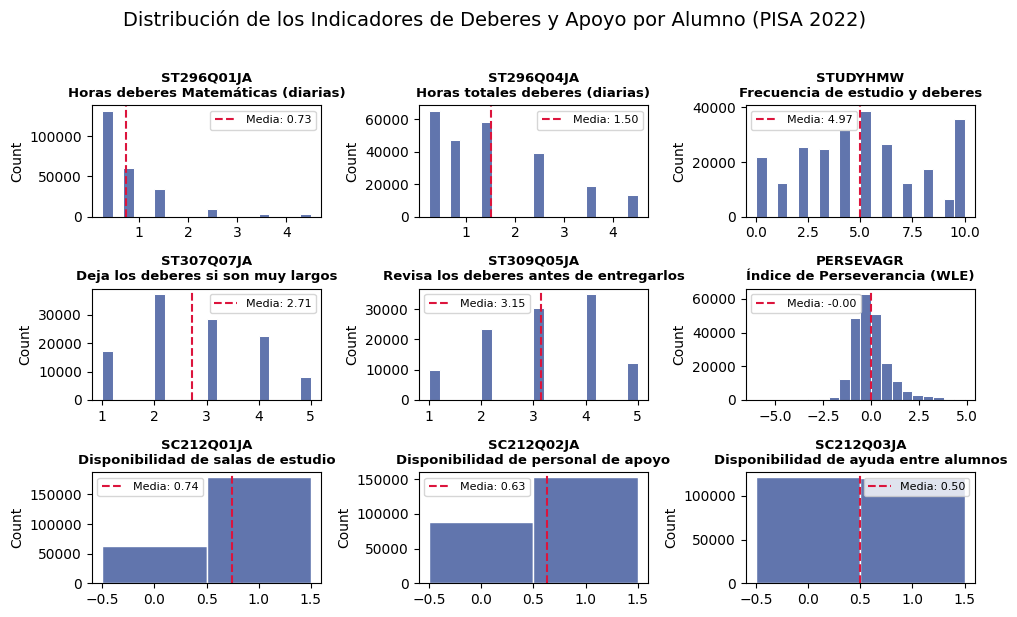

In [44]:
fig, axes = plt.subplots(3, 3, figsize=(10, 6))
axes = axes.flatten()

for idx, col in enumerate(columnas_a_revisar):
    ax = axes[idx]
    valores = df_analisis_esfuerzo_2022_lvl_alumno[col].dropna()

    if valores.empty:
        ax.set_title(f"{col}\nSin datos", fontsize=9.5)
        continue

    es_binaria = valores.isin([0, 1]).all()

    sns.histplot(
        x=valores,
        # kde=not es_binaria,
        discrete=es_binaria,
        bins=20 if not es_binaria else None,
        ax=ax,
        color='#1e3a8a',
        edgecolor='white',
        alpha=0.7
    )

    media_val = valores.mean()
    ax.axvline(
        media_val, color='crimson', linestyle='--', linewidth=1.5,
        label=f'Media: {media_val:.2f}'
    )
    ax.set_title(
        f"{col}\n{diccionario_indicadores.get(col, '')}",
        fontsize=9.5,
        fontweight='bold'
    )
    ax.set_xlabel('')
    ax.legend(fontsize=8)

plt.suptitle(
    'Distribución de los Indicadores de Deberes y Apoyo por Alumno (PISA 2022)',
    fontsize=14, y=1.02
)
plt.tight_layout()
plt.show()

In [117]:
#TODO RELLENAR EL MARKDOWN EXPLICATIVO

**Explicacion de lo visto**

## Analisis Bivariante

### Correlacion y curvas de saturación

<div style="
  background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%);
  backdrop-filter: blur(4px);
  -webkit-backdrop-filter: blur(4px);
  border-left: 5px solid rgba(128, 128, 128, 0.6);
  padding: 16px;
  border-radius: 8px;
  color: inherit;
  margin: 20px 0;
">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    💡 Correlacion de spearman
  </strong>
    Como paso previo al entrenamiento de un modelo no lineal , interesa identificar cualquier relación monótona (creciente o decreciente) entre las variables, aunque esta no lo hagan a un ritmo constante. El coeficiente de Spearman es ideal para capturar estas interacciones no lineales
</div>


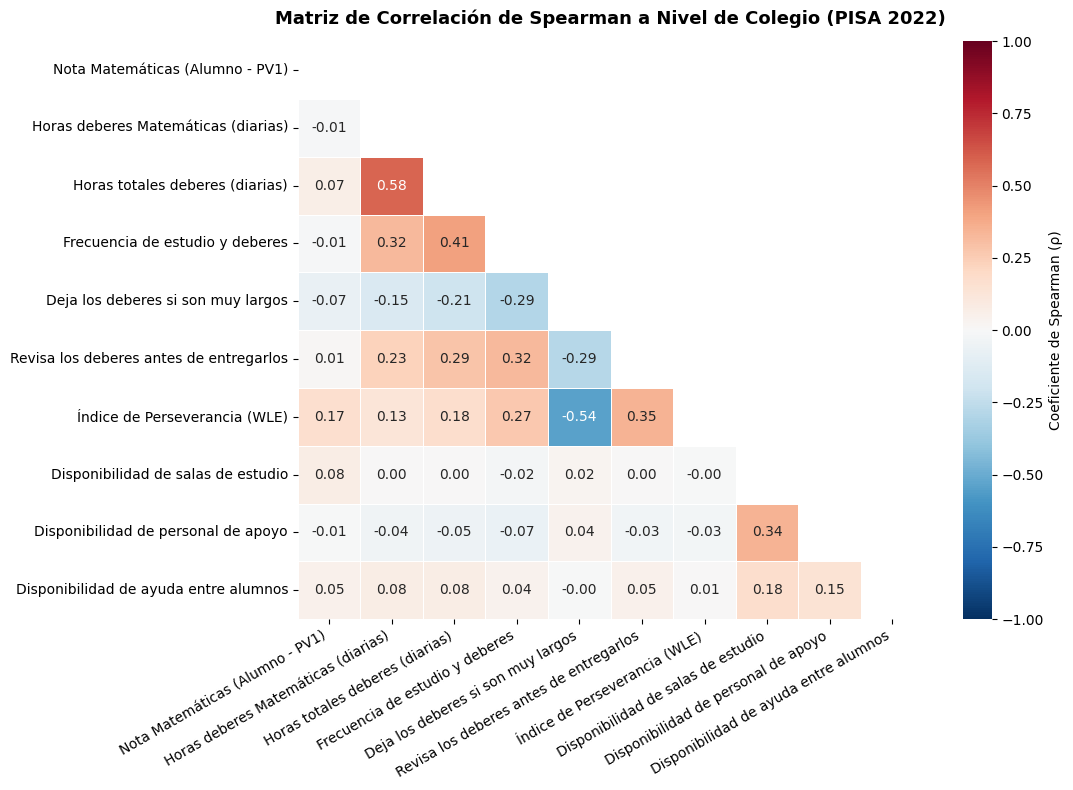

In [45]:
# Matriz de correlación de Spearman a nivel de COLEGIO (PISA 2022)
columnas_correlacion = [col_pv_math] + indicadores_alumno + indicadores_colegio

matriz_spearman = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_correlacion]
    .rename(columns=diccionario_indicadores)
    .corr(method='spearman')
)

plt.figure(figsize=(11, 8))
mascara = np.triu(np.ones_like(matriz_spearman, dtype=bool))
sns.heatmap(
    matriz_spearman, mask=mascara, annot=True, fmt=".2f",
    cmap="RdBu_r", vmin=-1, vmax=1, center=0,
    cbar_kws={'label': 'Coeficiente de Spearman (ρ)'}, linewidths=0.5
)
plt.title('Matriz de Correlación de Spearman a Nivel de Colegio (PISA 2022)', fontsize=13, pad=12, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Observaciones**

In [484]:
#TODO Rellenar observaciones de la correlacion

Como se relacionan los indices de deberes con la nota de matemáticas ?

C:\Users\victo\AppData\Local\Temp\ipykernel_35520\2925469547.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()
C:\Users\victo\AppData\Local\Temp\ipykernel_35520\2925469547.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend()


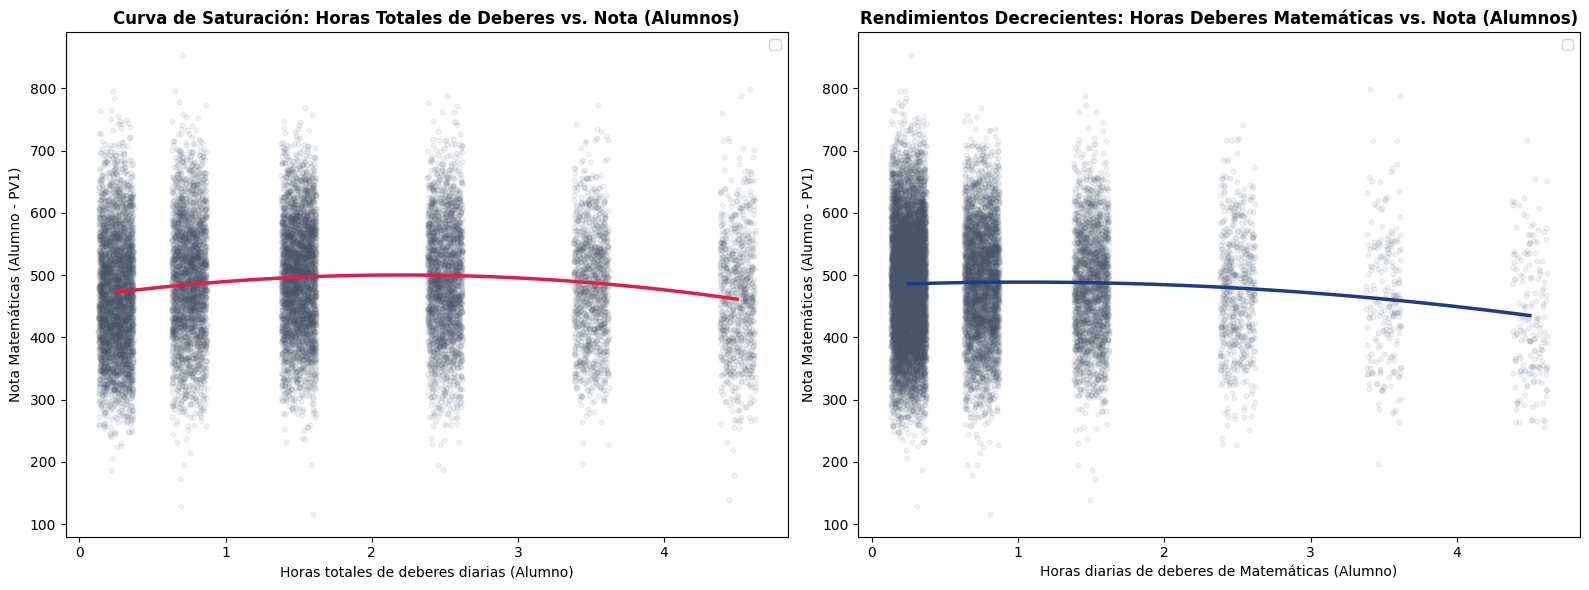

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Submuestra aleatoria para la nube de puntos (evita saturar matplotlib) y datos completos para la curva
df_plot_alumno = df_analisis_esfuerzo_2022_lvl_alumno.dropna(
    subset=[col_pv_math, 'ST296Q04JA', 'ST296Q01JA']
)
muestra_nube = df_plot_alumno.sample(
    n=min(15000, len(df_plot_alumno))
)

# Horas totales de deberes vs. PV1MATH
sns.regplot(
    data=muestra_nube, x='ST296Q04JA', y=col_pv_math,
    x_jitter=0.12, fit_reg=False, ax=axes[0],
    scatter_kws={'alpha': 0.08, 'color': '#475569', 's': 12}
)
sns.regplot(
    data=df_plot_alumno, x='ST296Q04JA', y=col_pv_math,
    order=2, scatter=False, ax=axes[0],
    line_kws={'color': '#e11d48', 'linewidth': 2.5, 'label': 'Tendencia cuadrática (Total alumnos)'}
)
axes[0].set_title('Curva de Saturación: Horas Totales de Deberes vs. Nota (Alumnos)', fontweight='bold')
axes[0].set_xlabel('Horas totales de deberes diarias (Alumno)')
axes[0].set_ylabel('Nota Matemáticas (Alumno - PV1)')
axes[0].legend()

# 2. Horas de deberes de Matemáticas vs. PV1MATH
sns.regplot(
    data=muestra_nube, x='ST296Q01JA', y=col_pv_math,
    x_jitter=0.12, fit_reg=False, ax=axes[1],
    scatter_kws={'alpha': 0.08, 'color': '#475569', 's': 12}
)
sns.regplot(
    data=df_plot_alumno, x='ST296Q01JA', y=col_pv_math,
    order=2, scatter=False, ax=axes[1],
    line_kws={'color': '#1e3a8a', 'linewidth': 2.5, 'label': 'Tendencia cuadrática (Total alumnos)'}
)
axes[1].set_title('Rendimientos Decrecientes: Horas Deberes Matemáticas vs. Nota (Alumnos)', fontweight='bold')
axes[1].set_xlabel('Horas diarias de deberes de Matemáticas (Alumno)')
axes[1].set_ylabel('Nota Matemáticas (Alumno - PV1)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
#TODO Rellenar observaciones e intentar mejorar la visualización de los datos (¿Cambiar la forma de la visualización?)

### Paradoja Simpson ( CAMBIAR NOMBRE)

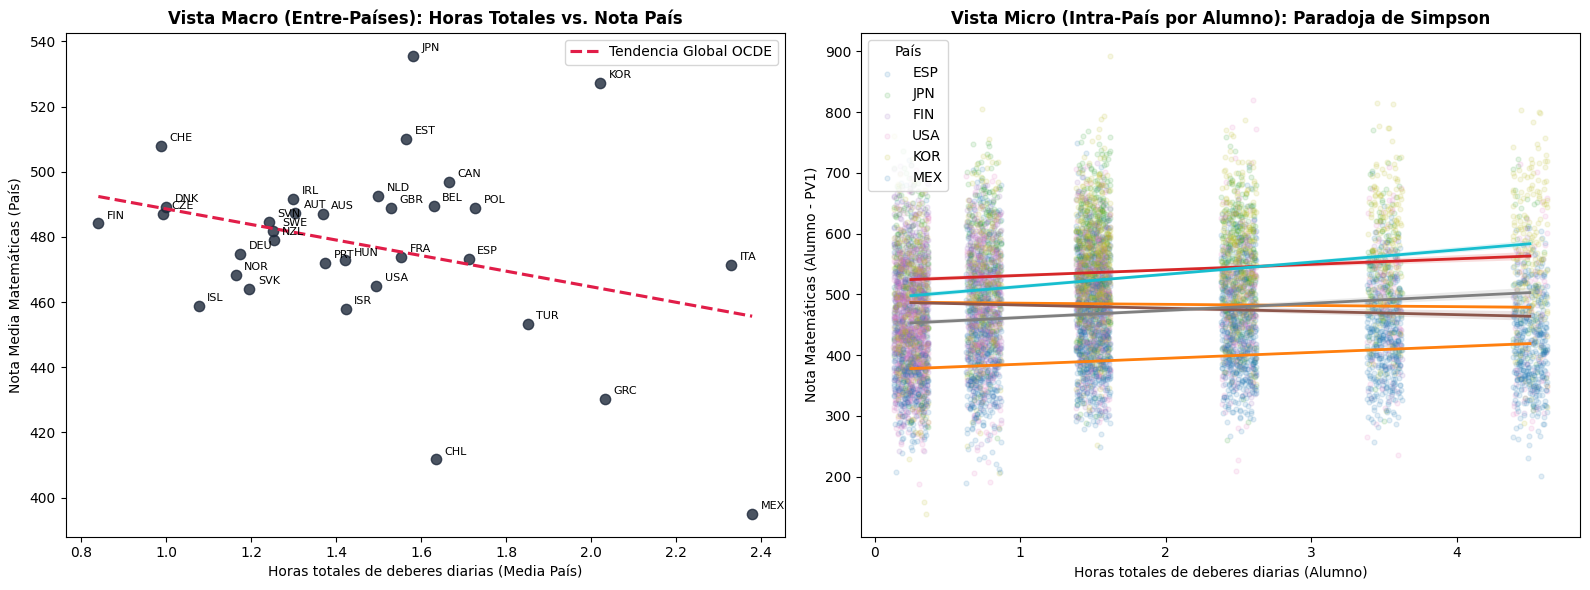

In [489]:
paises_referencia = ['ESP', 'JPN', 'FIN', 'USA', 'KOR', 'MEX']
df_simpson_alumno = df_analisis_esfuerzo_2022_lvl_alumno[
    df_analisis_esfuerzo_2022_lvl_alumno['CNT'].isin(paises_referencia)
].dropna(subset=['ST296Q04JA', col_pv_math])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Vista Macro (Nivel País - solo para EDA)
sns.regplot(
    data=df_analisis_esfuerzo_2022_lvl_pais,
    x='ST296Q04JA', y='media_math_pais', ax=axes[0],
    scatter_kws={'s': 55, 'color': '#1e293b'},
    line_kws={'color': '#e11d48', 'linestyle': '--', 'label': 'Tendencia Global OCDE'},
    ci=False
)
for _, fila in df_analisis_esfuerzo_2022_lvl_pais.dropna(subset=['ST296Q04JA', 'media_math_pais']).iterrows():
    axes[0].text(fila['ST296Q04JA'] + 0.02, fila['media_math_pais'] + 1.5, fila['CNT'], fontsize=8)

axes[0].set_title('Vista Macro (Entre-Países): Horas Totales vs. Nota País', fontweight='bold')
axes[0].set_xlabel('Horas totales de deberes diarias (Media País)')
axes[0].set_ylabel('Nota Media Matemáticas (País)')
axes[0].legend()

# Vista Micro (Intra-País por Alumno)
for pais in paises_referencia:
    sub_pais = df_simpson_alumno[df_simpson_alumno['CNT'] == pais]
    if sub_pais.empty:
        continue
    # Submuestra de puntos con jitter para visualización limpia
    sub_muestra = sub_pais.sample(n=min(1500, len(sub_pais)), random_state=42)
    sns.regplot(
        data=sub_muestra, x='ST296Q04JA', y=col_pv_math,
        x_jitter=0.12, fit_reg=False, ax=axes[1],
        label=pais, scatter_kws={'alpha': 0.12, 's': 12},
        
    )
    # Recta de regresión ajustada sobre todos los alumnos del país
    sns.regplot(
        data=sub_pais, x='ST296Q04JA', y=col_pv_math,
        scatter=False, ax=axes[1], line_kws={'linewidth': 2},
        
    )

axes[1].set_title('Vista Micro (Intra-País por Alumno): Paradoja de Simpson', fontweight='bold')
axes[1].set_xlabel('Horas totales de deberes diarias (Alumno)')
axes[1].set_ylabel('Nota Matemáticas (Alumno - PV1)')
axes[1].legend(title='País')

plt.tight_layout()
plt.show()

"La introducción de un ajuste cuadrático global a nivel de centros educativos (Gráfico de Curva de Saturación) valida empíricamente la hipótesis de la 'U invertida'. Al analizar la masa global de colegios sin la rigidez de una regresión lineal, se observa un punto de inflexión óptimo situado en torno a las 2 horas de deberes diarios totales, a partir del cual el rendimiento académico decrece de forma notable. Este umbral es aún más crítico al aislar los deberes específicos de la materia (Gráfico de Rendimientos Decrecientes), donde el exceso de carga horaria en matemáticas muestra una pendiente negativa casi inmediata, sugiriendo fatiga cognitiva o saturación pedagógica.
La convivencia de este comportamiento curvilíneo global con las pendientes positivas intra-país de la Paradoja de Simpson revela que el tramo descendente de la curva de saturación está fuertemente influenciado por la distribución transnacional de los datos: los países con rendimientos promedio más bajos ocupan de manera desproporcionada el extremo derecho del eje de absorción horaria, evidenciando que las cargas horarias excesivas a nivel de sistema macro coexisten con entornos educativos de menor eficacia estructural."


## Perseverancia

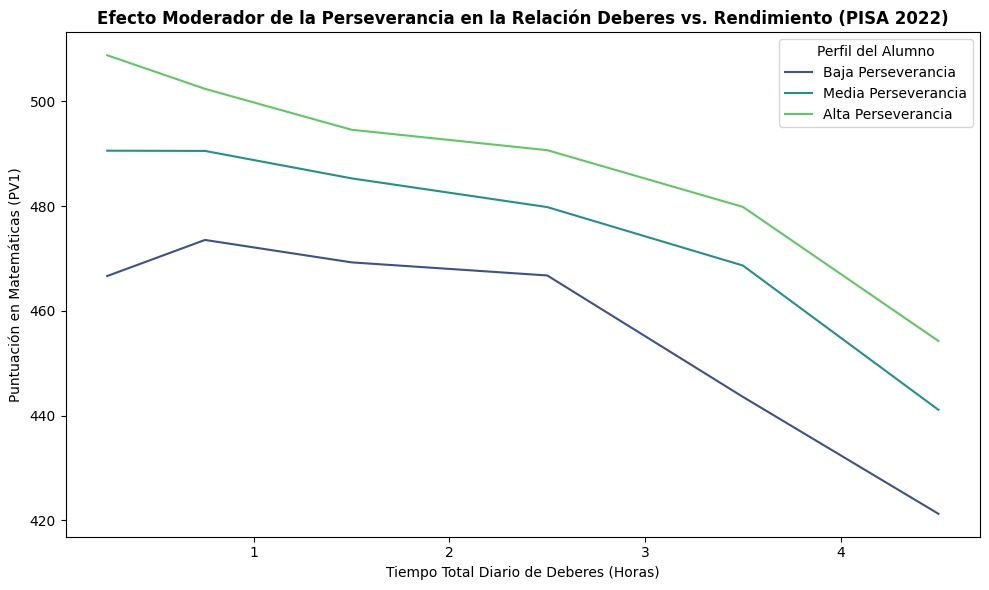

In [50]:
# Creamos una segmentación de perseverancia en 3 grupos (Baja, Media, Alta)
df_analisis_esfuerzo_2022_lvl_alumno['nivel_perseverancia'] = pd.qcut(
    df_analisis_esfuerzo_2022_lvl_alumno['PERSEVAGR'], 
    q=3, 
    labels=['Baja Perseverancia', 'Media Perseverancia', 'Alta Perseverancia']
)

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=df_analisis_esfuerzo_2022_lvl_alumno,
    # x='ST296Q04JA', # Horas totales de deberes
    x='ST296Q01JA', # Horas totales de deberes mates
    y='PV1MATH',    # Nota de matemáticas
    hue='nivel_perseverancia',
    palette='viridis',
    errorbar=None
)
plt.title('Efecto Moderador de la Perseverancia en la Relación Deberes vs. Rendimiento (PISA 2022)', fontsize=12, fontweight='bold')
plt.xlabel('Tiempo Total Diario de Deberes (Horas)')
plt.ylabel('Puntuación en Matemáticas (PV1)')
plt.legend(title='Perfil del Alumno')
plt.tight_layout()
plt.show()

* Comportamiento en forma de U invertida: Para los tres perfiles de perseverancia, la relación entre el tiempo dedicado a los deberes y el rendimiento no es lineal. Las puntuaciones aumentan inicialmente al dedicar algo de tiempo a los deberes, alcanzando un punto óptimo o máximo alrededor de 1.5 horas diarias.

* Impacto de la perseverancia: Se observa que, independientemente de la cantidad de tiempo invertida, los alumnos con alta perseverancia obtienen de manera constante mejores resultados académicos que aquellos con menor perseverancia


# Perfil de paises segun esfuerzo

In [ ]:
#TODO Toquetear esto para no dejar este chorizo

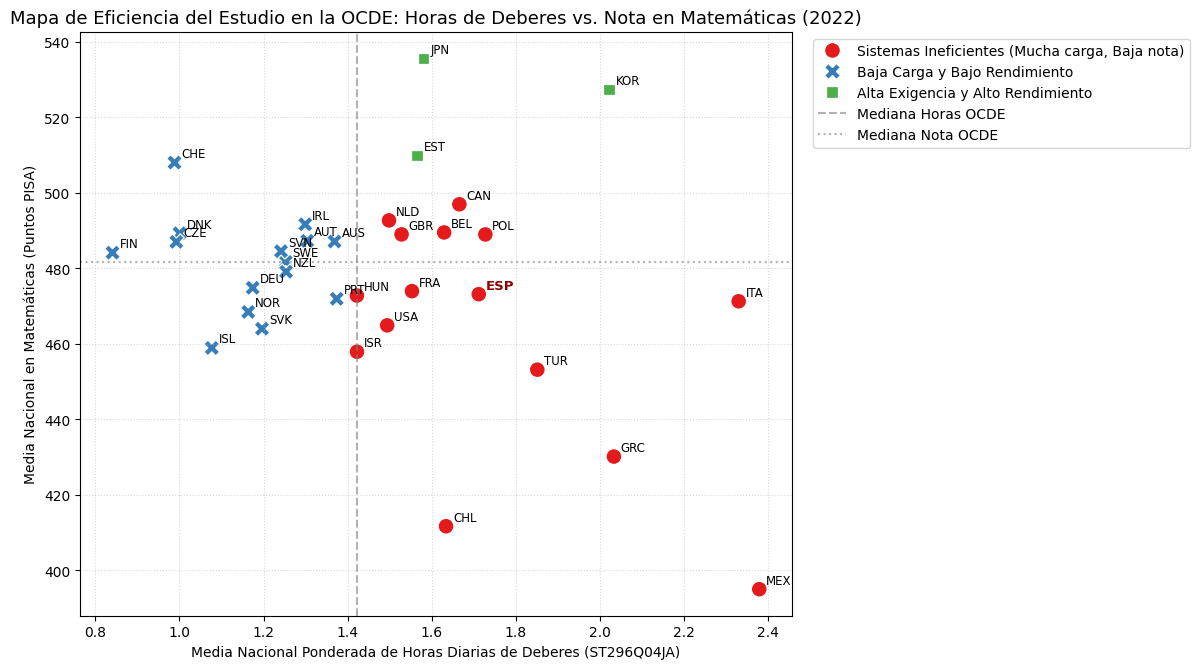

In [ ]:
df_cluster = df_analisis_esfuerzo_2022_lvl_pais[['CNT', 'ST296Q04JA', 'media_math_pais', 'SC212Q02JA']].dropna(
    subset=['ST296Q04JA', 'media_math_pais']
).copy()

#TODO COMPROBAR LOS PAISES RESULTANTES AL HACER EL DROPNA Y COMPROBAR ESAS VARIABLES

scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(df_cluster[['ST296Q04JA', 'media_math_pais']])

# Ajuste de K-Means en 4 tipologías educativas
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_cluster['Cluster'] = kmeans.fit_predict(X_cluster_scaled)

# Etiquetado semántico automático de los clústeres según sus centroides respecto a la mediana OCDE
centroides = df_cluster.groupby('Cluster')[['ST296Q04JA', 'media_math_pais']].mean()
med_horas = df_cluster['ST296Q04JA'].median()
med_nota = df_cluster['media_math_pais'].median()

def asignar_perfil_sistema(c):
    h, n = centroides.loc[c, 'ST296Q04JA'], centroides.loc[c, 'media_math_pais']
    if n >= med_nota and h < med_horas:
        return 'Alta Eficiencia (Pocas horas, Alta nota)'
    elif n >= med_nota and h >= med_horas:
        return 'Alta Exigencia y Alto Rendimiento'
    elif n < med_nota and h >= med_horas:
        return 'Sistemas Ineficientes (Mucha carga, Baja nota)'
    return 'Baja Carga y Bajo Rendimiento'

df_cluster['Tipologia_Sistema'] = df_cluster['Cluster'].map({c: asignar_perfil_sistema(c) for c in centroides.index})

plt.figure(figsize=(12, 6.8))
sns.scatterplot(
    data=df_cluster, x='ST296Q04JA', y='media_math_pais',
    hue='Tipologia_Sistema', style='Tipologia_Sistema', s=130, palette='Set1'
)
plt.axvline(med_horas, color='grey', linestyle='--', alpha=0.6, label='Mediana Horas OCDE')
plt.axhline(med_nota, color='grey', linestyle=':', alpha=0.6, label='Mediana Nota OCDE')

#Marcamos españa
for _, fila in df_cluster.iterrows():
    es_esp = fila['CNT'] == 'ESP'
    plt.annotate(
        fila['CNT'],
        (fila['ST296Q04JA'], fila['media_math_pais']),
        xytext=(5, 4), textcoords='offset points',
        fontsize=9.5 if es_esp else 8.5,
        fontweight='bold' if es_esp else 'normal',
        color='darkred' if es_esp else 'black'
    )

plt.title('Mapa de Eficiencia del Estudio en la OCDE: Horas de Deberes vs. Nota en Matemáticas (2022)', fontsize=13)
plt.xlabel('Media Nacional Ponderada de Horas Diarias de Deberes (ST296Q04JA)')
plt.ylabel('Media Nacional en Matemáticas (Puntos PISA)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

** Esto da al análisis de los siguientes años, ha sido así siempre, ha ido cambiando ?'

## 5. Selección de Variables y Explicabilidad (XGBoost + SHAP) -> Cambiarlo a nivl de colegio y revisar

Para evaluar rigurosamente la capacidad predictiva de los indicadores de deberes a nivel de estrato:
1. **Validación Cruzada Ponderada (5-Fold CV):** Aplicamos regularización explícita (`max_depth=3`, `learning_rate=0.05`, `subsample=0.8`) acorde al tamaño muestral ($N = 422$ estratos) y ponderamos tanto el ajuste como las métricas de evaluación ($R^2$, RMSE y MAE) mediante el peso poblacional `SENWT`.
2. **Explicabilidad mediante Valores SHAP (*SHapley Additive exPlanations*):** A diferencia de la ganancia (`gain`) clásica de los árboles, que solo mide magnitud, los valores SHAP descomponen el signo y la no-linealidad del impacto de cada indicador sobre la puntuación predicha de Matemáticas.

📈 Métricas de Validación Cruzada a Nivel Colegio (5-Fold Ponderado por SENWT_col):
   • R² medio   : 0.146 (± 0.002)
   • RMSE medio : 88.85 puntos PISA
   • MAE medio  : 71.67 puntos PISA


,Codigo,Indicador,Importancia Gain (%)
0,ST296Q04JA,Horas totales deberes (diarias),23.26
1,ST296Q01JA,Horas deberes Matemáticas (diarias),20.18
2,STUDYHMW,Frecuencia de estudio y deberes,18.57
3,SC212Q01JA,Disponibilidad de salas de estudio,11.67
4,PERSEVAGR,Índice de Perseverancia (WLE),11.26
5,SC212Q02JA,Disponibilidad de personal de apoyo,4.89
6,SC212Q03JA,Disponibilidad de ayuda entre alumnos,3.59
7,ST307Q07JA,Deja los deberes si son muy largos,3.53
8,ST309Q05JA,Revisa los deberes antes de entregarlos,3.05


C:\Users\victo\AppData\Local\Temp\ipykernel_35520\2917666095.py:59: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, features_traducidas, show=False)


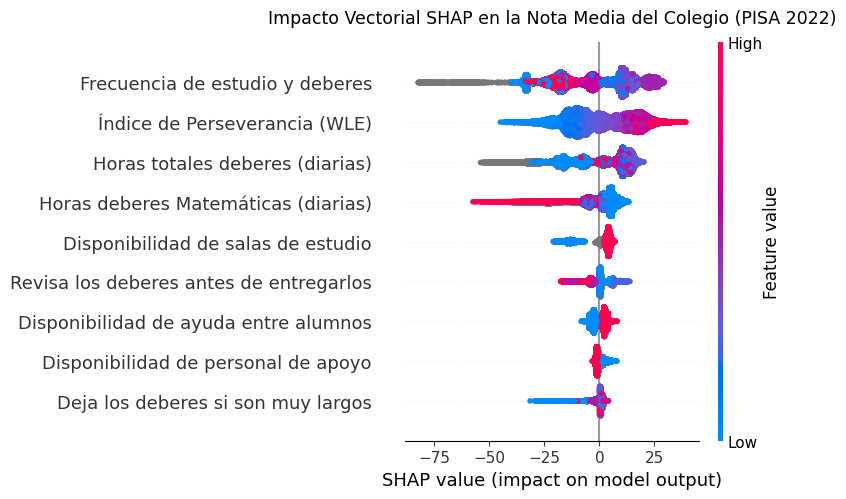

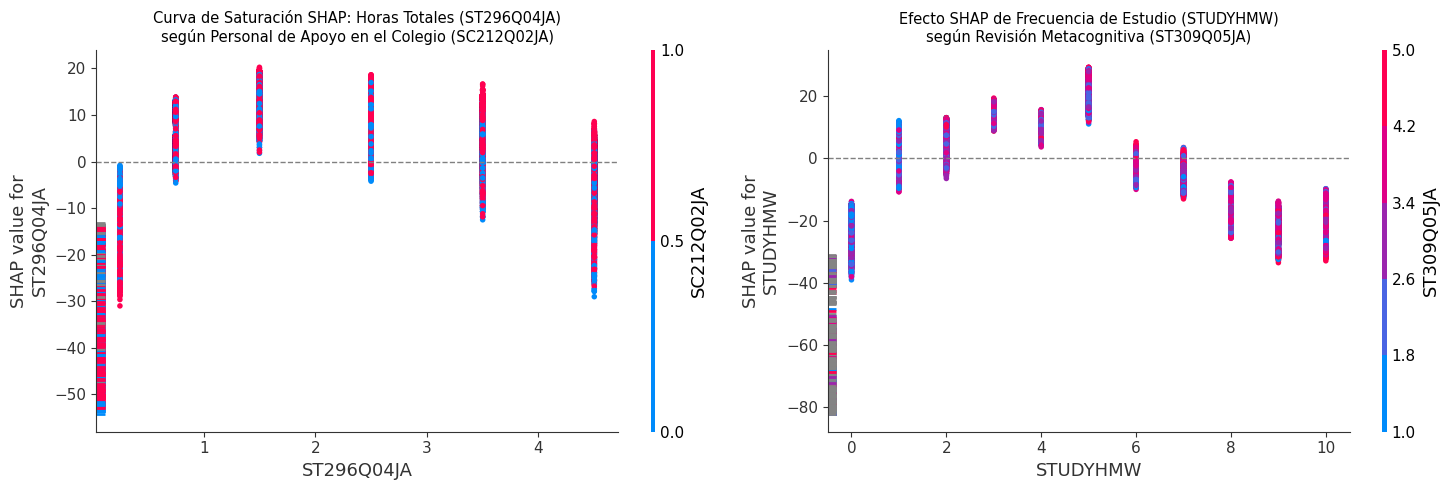

In [47]:
# Preparación de matrices a nivel de COLEGIO
df_modelo_2022 = df_analisis_esfuerzo_2022_lvl_alumno.dropna(subset=[col_pv_math]).copy()

features_2022 = df_modelo_2022[indicadores_alumno + indicadores_colegio].copy()
target_2022 = df_modelo_2022[col_pv_math].copy()
pesos_2022 = df_modelo_2022['SENWT'].fillna(1.0).copy()

params_xgb = dict(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    importance_type='gain',
    random_state=42
)

# 1. Validación Cruzada Ponderada (5-Fold CV sobre Colegios)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2_lista, rmse_lista, mae_lista = [], [], []

for tr_idx, val_idx in kf.split(features_2022):
    mod_cv = xgb.XGBRegressor(**params_xgb)
    mod_cv.fit(
        features_2022.iloc[tr_idx], target_2022.iloc[tr_idx],
        sample_weight=pesos_2022.iloc[tr_idx]
    )
    preds = mod_cv.predict(features_2022.iloc[val_idx])
    w_val = pesos_2022.iloc[val_idx]
    
    r2_lista.append(r2_score(target_2022.iloc[val_idx], preds, sample_weight=w_val))
    rmse_lista.append(root_mean_squared_error(target_2022.iloc[val_idx], preds, sample_weight=w_val))
    mae_lista.append(mean_absolute_error(target_2022.iloc[val_idx], preds, sample_weight=w_val))

print(f"📈 Métricas de Validación Cruzada a Nivel Colegio (5-Fold Ponderado por SENWT_col):")
print(f"   • R² medio   : {np.mean(r2_lista):.3f} (± {np.std(r2_lista):.3f})")
print(f"   • RMSE medio : {np.mean(rmse_lista):.2f} puntos PISA")
print(f"   • MAE medio  : {np.mean(mae_lista):.2f} puntos PISA")

# 2. Ajuste del modelo final sobre todos los colegios de 2022
modelo_deberes = xgb.XGBRegressor(**params_xgb)
modelo_deberes.fit(features_2022, target_2022, sample_weight=pesos_2022)

tabla_importancia = pd.DataFrame({
    'Codigo': features_2022.columns,
    'Indicador': [diccionario_indicadores.get(c, c) for c in features_2022.columns],
    'Importancia Gain (%)': (modelo_deberes.feature_importances_ * 100).round(2)
}).sort_values('Importancia Gain (%)', ascending=False).reset_index(drop=True)

display(tabla_importancia)

# 3. Explicabilidad Vectorial SHAP (Beeswarm + Dependencia Parcial)
explainer = shap.TreeExplainer(modelo_deberes)
shap_values = explainer.shap_values(features_2022)
features_traducidas = features_2022.rename(columns=diccionario_indicadores)

plt.figure(figsize=(11, 5.5))
shap.summary_plot(shap_values, features_traducidas, show=False)
plt.title('Impacto Vectorial SHAP en la Nota Media del Colegio (PISA 2022)', fontsize=12.5, pad=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
shap.dependence_plot(
    'ST296Q04JA', shap_values, features_2022,
    interaction_index='SC212Q02JA', ax=axes[0], show=False
)
axes[0].axhline(0, color='grey', linestyle='--', linewidth=1)
axes[0].set_title('Curva de Saturación SHAP: Horas Totales (ST296Q04JA)\nsegún Personal de Apoyo en el Colegio (SC212Q02JA)', fontsize=10.5)

shap.dependence_plot(
    'STUDYHMW', shap_values, features_2022,
    interaction_index='ST309Q05JA', ax=axes[1], show=False
)
axes[1].axhline(0, color='grey', linestyle='--', linewidth=1)
axes[1].set_title('Efecto SHAP de Frecuencia de Estudio (STUDYHMW)\nsegún Revisión Metacognitiva (ST309Q05JA)', fontsize=10.5)

plt.tight_layout()
plt.show()

INTERPRETACION DE LOS RESULTADOS : TENGO QUE DEFINIR LAS VARIABLES DE MAYOR IMPORTANCIA Y DECIR PORQUE NO SE PUEDEN ESCOGER PARA OTROS AÑOS()

## 5. Armonización de Datos a Nivel de Alumno (PISA 2012–2022)


<div style="background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%); border-left: 5px solid rgba(128, 128, 128, 0.6); padding: 16px; border-radius: 8px; margin: 20px 0;">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    ⚠️ Criterio de Selección para el Panel Longitudinal (2012–2022)
  </strong>
  Los ítems metacognitivos (<code>ST309Q05JA</code>, <code>ST307Q07JA</code>) y el índice <code>STUDYHMW</code> de 2022 no disponen de equivalencia directa en las cuatro olas históricas. Por ello, seleccionamos para el panel longitudinal las dos dimensiones clave con continuidad demostrada entre 2012 y 2022:
  <ul>
    <li><b>Dimensión Estudiante:</b> <code>tiempo_deberes_totales_diarios</code> (horas diarias estimadas en escala acotada [0, 4.5]).</li>
    <li><b>Dimensión Escuela:</b> <code>dispone_personal_apoyo</code> (indicador binario [0, 1] de apoyo docente/refuerzo en el centro).</li>
  </ul>
</div>

Tabla de Equivalencias Metodológicas (Crosswalk 2012–2022)

| Edición PISA | Variable `tiempo_deberes_totales_diarios` | Variable `dispone_personal_apoyo` | Regla de Armonización en Nivel Alumno |
| :--- | :--- | :--- | :--- |
| **PISA 2022** | `ST296Q04JA` | `SC212Q02JA` | Mapeo de tramos ordinales (1–6) a puntos medios $[0.25, 4.50]\text{ h}$. Binaria colegio: $1 \rightarrow 1.0$, $2 \rightarrow 0.0$. |
| **PISA 2018** | `EC158Q01HA` + `EC159Q01HA` | `SC052Q02NA` | Conversión de categorías a horas $(-1)$, suma con `min_count=1` de mañana y tarde acotada a $[0.25, 4.50]\text{ h}$. Binaria colegio: $1 \rightarrow 1.0$, $2 \rightarrow 0.0$. |
| **PISA 2015** | `ST071Q01NA` a `ST071Q05NA` | `SC052Q02NA` | Suma semanal de asignaturas con `min_count=1` dividida entre $5$ días lectivos y acotada a $[0.0, 4.50]\text{ h}$ para neutralizar *outliers*. Binaria colegio: $1 \rightarrow 1.0$, $2 \rightarrow 0.0$. |
| **PISA 2012** | `ST57Q01`, `ST57Q02`, `ST57Q05` | `SC20Q01` + `SC21Q05` *(Proxy)* | Suma semanal de modalidades de deberes dividida entre $5$ días lectivos, acotada a $[0.0, 4.50]\text{ h}$. Proxy colegio: $1.0$ si `SC20Q01 == 1` y `SC21Q05` $\in \{2, 3\}$, $0.0$ en caso contrario. |

### Funcion Auxiliar 

In [456]:
#Columnas que se mantienen en todas las ediciones
columnas_estandar_alumno = [
    'CNT', 'CNTSCHID', 'CNTSTUID', 'year',
    'W_FSTUWT', 'SENWT',
    'tiempo_deberes_totales_diarios', 'dispone_personal_apoyo'
]

def obtener_primer_pv_math(ruta_parquet):
    """Devuelve el nombre del primer Plausible Value de Matemáticas en el esquema del Parquet."""
    nombres_pv_mates = set(columnas_pv('MATH'))
    cols_pv = [c for c in pq.read_schema(ruta_parquet).names if c in nombres_pv_mates]
    return cols_pv[0]

## Preparacion de datos equivalentes para PISA 2022

In [457]:
#Partimos de la tabla inicial a nivel de colegios para armonizar el nombre de las variables y quedarnos únicamente con lo relativo al esfuerzo
df_base_2022_alumno = df_analisis_esfuerzo_2022_lvl_alumno.rename(columns={
    col_pv_math: 'PV1MATH',
    'ST296Q04JA': 'tiempo_deberes_totales_diarios',
    'SC212Q02JA': 'dispone_personal_apoyo'
})[columnas_estandar_alumno].copy()

display(df_base_2022_alumno.head())
display(df_base_2022_alumno.shape)


,CNT,CNTSCHID,CNTSTUID,year,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,dispone_personal_apoyo
0,AUS,3600477,3600001,2022,21.49,0.41,0.75,1.00
1,AUS,3600016,3600002,2022,26.35,0.50,3.50,1.00
2,AUS,3600669,3600004,2022,34.43,0.65,3.50,1.00
3,AUS,3600495,3600006,2022,30.61,0.58,NaN,1.00
4,AUS,3600325,3600008,2022,8.86,0.17,0.25,0.00


(268610, 8)

# Obtención de datos equivalentesPISA 2012

### Construcción del equivalente Tiempo Total de Deberes en PISA 2012

En PISA 2012, el cuestionario dividía el tiempo de estudio semanal fuera de clase en varios ítems independientes. Para obtener una métrica armonizada y realista del tiempo total diario dedicado a los deberes (comparable con las ediciones posteriores), se agrupan las distintas modalidades de deberes y ayuda en el entorno familiar:

* **`ST57Q01`**: Trabajo autónomo / Deberes (*Homework*)
* **`ST57Q02`**: Deberes guiados o supervisados (*Guided Homework*)
* **`ST57Q05`**: Estudio o deberes con ayuda de los padres (*With Parent*)

**Regla de codificación:**
Se calcula la suma horizontal de las horas semanales reportadas en estas tres modalidades para capturar el volumen real de estudio en casa. Este total semanal se divide entre 5 (días lectivos) para estimar la carga diaria. Para evitar sesgos a la baja, la suma requiere un mínimo de una respuesta válida (`min_count=1`).

$$tiempo\_deberes\_totales\_diarios = \frac{ST57Q01 + ST57Q02 + ST57Q05}{5}$$


### Construcción del equivalente Apoyo Escolar en PISA 2012

Dada la ausencia estructural de la variable sobre apoyo para los deberes en 2012, obtenemos su equivalente mediante una transformación de las variables de refuerzo matemático del Cuestionario de Directores de 2012:

* **`SC20Q01`**: *"Additional maths lessons"* (1 = Sí, 2 = No)
* **`SC21Q05`**: *"Purpose of additional maths lessons"* (1 = Enrichment, 2 = Remedial, 3 = Both enrichment and remedial, 4 = Without differentiation)

**Regla de codificación:**
Se codificará con valor **1** (dispone de apoyo) a aquellos centros que ofrezcan clases adicionales de matemáticas enfocadas en el refuerzo compensatorio (*Remedial*) o en una modalidad mixta.

$$dispone\_personal\_apoyo =  \begin{cases}  1 & \text{si } SC20Q01 = 1 \text{ y } SC21Q05 \in \{2, 3\} \\  0 & \text{en otro caso}  \end{cases}$$

In [458]:
ruta_est_2012 = RUTA_DATOS_ANUALES / 'pisa2012_estudiantes.parquet'
ruta_col_2012 = RUTA_DATOS_ANUALES / 'pisa2012_colegios.parquet'
pv1_2012 = obtener_primer_pv_math(ruta_est_2012)

esquema_2012 = pq.read_schema(ruta_est_2012).names
columnas_tiempo_2012 = [c for c in ['ST57Q01', 'ST57Q02', 'ST57Q05'] if c in esquema_2012]

cols_est_2012 = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + columnas_tiempo_2012
))
df_est_2012 = pd.read_parquet(ruta_est_2012, columns=cols_est_2012).rename(columns={pv1_2012: 'PV1MATH'})
df_col_2012 = pd.read_parquet(
    ruta_col_2012, columns=claves_colegio + ['SC20Q01', 'SC21Q05']
).drop_duplicates(subset=claves_colegio)


In [459]:
display(df_est_2012.head(2))
display(df_col_2012.head(2))

,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,SENWT,ST57Q01,ST57Q02,ST57Q05
0,AUS,00001,0000001,33.39,0.67,5.00,0.00,1.00
1,AUS,00002,0000001,33.39,0.67,5.00,0.00,0.00


,CNT,CNTSCHID,SC20Q01,SC21Q05
0,AUS,0000001,1.00,3.00
1,AUS,0000002,2.00,NaN


In [460]:

# Transformación de índices 2012
df_est_2012['tiempo_deberes_totales_diarios'] = (
    df_est_2012[columnas_tiempo_2012].sum(axis=1, min_count=1) / 5
).clip(lower=0.0, upper=4.5)

condicion_refuerzo_2012 = (df_col_2012['SC20Q01'] == 1) & (df_col_2012['SC21Q05'].isin([2, 3]))
df_col_2012['dispone_personal_apoyo'] = np.where(condicion_refuerzo_2012, 1.0, 0.0)
df_col_2012.loc[df_col_2012['SC20Q01'].isna(), 'dispone_personal_apoyo'] = np.nan

In [461]:
df_base_2012_alumno = df_est_2012.merge(
    df_col_2012[claves_colegio + ['dispone_personal_apoyo']],
    on=claves_colegio, how='left', validate='many_to_one'
)
df_base_2012_alumno['year'] = 2012
df_base_2012_alumno = df_base_2012_alumno[columnas_estandar_alumno]

del df_est_2012, df_col_2012
gc.collect()

7788

In [462]:
display(df_base_2012_alumno.head())
display(df_base_2012_alumno.shape)


,CNT,CNTSCHID,CNTSTUID,year,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,dispone_personal_apoyo
0,AUS,0000001,00001,2012,33.39,0.67,1.20,1.00
1,AUS,0000001,00002,2012,33.39,0.67,1.00,1.00
2,AUS,0000001,00003,2012,33.39,0.67,4.50,1.00
3,AUS,0000001,00004,2012,35.22,0.70,1.80,1.00
4,AUS,0000001,00005,2012,35.22,0.70,2.20,1.00


(290158, 8)

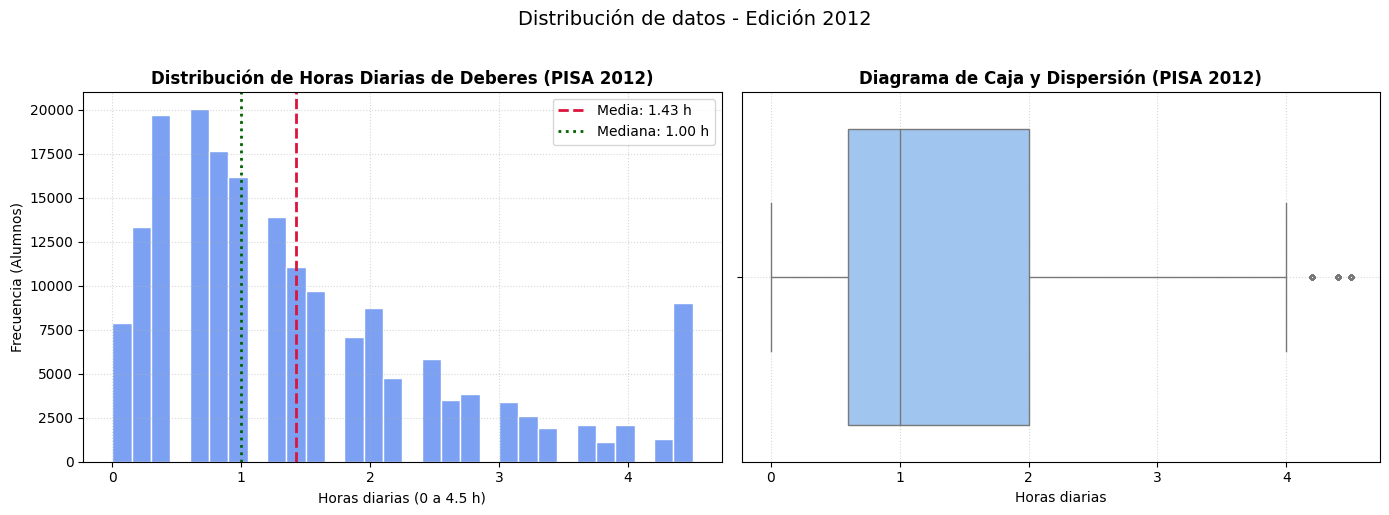

In [463]:
# Extraemos la serie de tiempo limpia excluyendo nulos
serie_2018 = df_base_2012_alumno['tiempo_deberes_totales_diarios'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histograma con curva de densidad (KDE)
sns.histplot(
    serie_2018,
    kde=False,
    bins=30,
    color='#2563eb',
    edgecolor='white',
    alpha=0.6,
    ax=axes[0]
)
media_val = serie_2018.mean()
mediana_val = serie_2018.median()

axes[0].axvline(media_val, color='crimson', linestyle='--', linewidth=2, label=f'Media: {media_val:.2f} h')
axes[0].axvline(mediana_val, color='darkgreen', linestyle=':', linewidth=2, label=f'Mediana: {mediana_val:.2f} h')
axes[0].set_title('Distribución de Horas Diarias de Deberes (PISA 2012)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Horas diarias (0 a 4.5 h)')
axes[0].set_ylabel('Frecuencia (Alumnos)')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.5)

# 2. Boxplot (Diagrama de caja para cuartiles y dispersión)
sns.boxplot(
    x=serie_2018,
    color='#93c5fd',
    ax=axes[1],
    fliersize=3
)
axes[1].set_title('Diagrama de Caja y Dispersión (PISA 2012)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Horas diarias')
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Distribución de datos - Edición 2012', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Obtención de datos equivalentes PISA 2015

### Construcción del equivalente Tiempo Total de Deberes en PISA 2015

En PISA 2015 la OCDE no preguntó por el tiempo de estudio global en una sola variable, sino que desglosó las horas semanales dedicadas a los deberes por materias. Para obtener la métrica equivalente al tiempo total diario, aplicamos una transformación matemática agregando los cinco ítems del cuestionario del estudiante:

* **`ST071Q01NA`**: Horas semanales en Ciencias
* **`ST071Q02NA`**: Horas semanales en Matemáticas
* **`ST071Q03NA`**: Horas semanales en Lectura/Lengua

**Regla de codificación:**
Se calcula la suma horizontal de las horas reportadas en todas las materias para obtener el volumen semanal total, y se divide entre 5 (días lectivos) para estimar la carga diaria. Para evitar sesgos a la baja, la suma requiere un mínimo de una respuesta válida (`min_count=1`).

$$\text{tiempo\_deberes\_totales\_diarios} = \frac{\sum_{i=1}^{5} \text{ST071Q0}i\text{NA}}{5}$$

Queremos comprobar que se contempla en outhrs por eso hacemos las comprobaciones de los cálculos
*En* **PISA 2022** *, la propia OCDE acota el tiempo diario de deberes a un máximo de* **4,5 horas/día** *[PISA 2022 Results vol II.pdf].* 
La OCDE fijó un tope máximo (*top-coding*) de **70** **horas semanales** para el valor de `OUTHOURS` en los microdatos

In [493]:
ruta_est_2015 = RUTA_DATOS_ANUALES / 'pisa2015_estudiantes.parquet'
ruta_col_2015 = RUTA_DATOS_ANUALES / 'pisa2015_colegios.parquet'
pv1_2015 = obtener_primer_pv_math(ruta_est_2015)

# Separamos las listas para hacer las dos pruebas
cols_5_materias = [f'ST071Q0{i}NA' for i in range(1, 6)]
cols_3_materias = ['ST071Q01NA', 'ST071Q02NA', 'ST071Q03NA']

# Cargamos todas las necesarias (las 5 materias + OUTHOURS)
cols_est_2015 = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + cols_5_materias + ['OUTHOURS']
))

# Lectura de Datos
df_est_2015 = pd.read_parquet(ruta_est_2015, columns=cols_est_2015).rename(columns={pv1_2015: 'PV1MATH'})
df_col_2015 = pd.read_parquet(
    ruta_col_2015, columns=claves_colegio + ['SC052Q02NA']
).drop_duplicates(subset=claves_colegio)

In [494]:
# Cálculos de las tres versiones
# Oficial de la OCDE
df_est_2015['outhours_oficial'] = (df_est_2015['OUTHOURS'] / 5).clip(lower=0.0, upper=4.5)

# Manual 1: Suma de 5 materias
df_est_2015['manual_5_materias'] = (
    df_est_2015[cols_5_materias].sum(axis=1, min_count=1) / 5
).clip(lower=0.0, upper=4.5)

# Manual 2: Suma de 3 materias
df_est_2015['manual_3_materias'] = (
    df_est_2015[cols_3_materias].sum(axis=1, min_count=1) / 5
).clip(lower=0.0, upper=4.5)


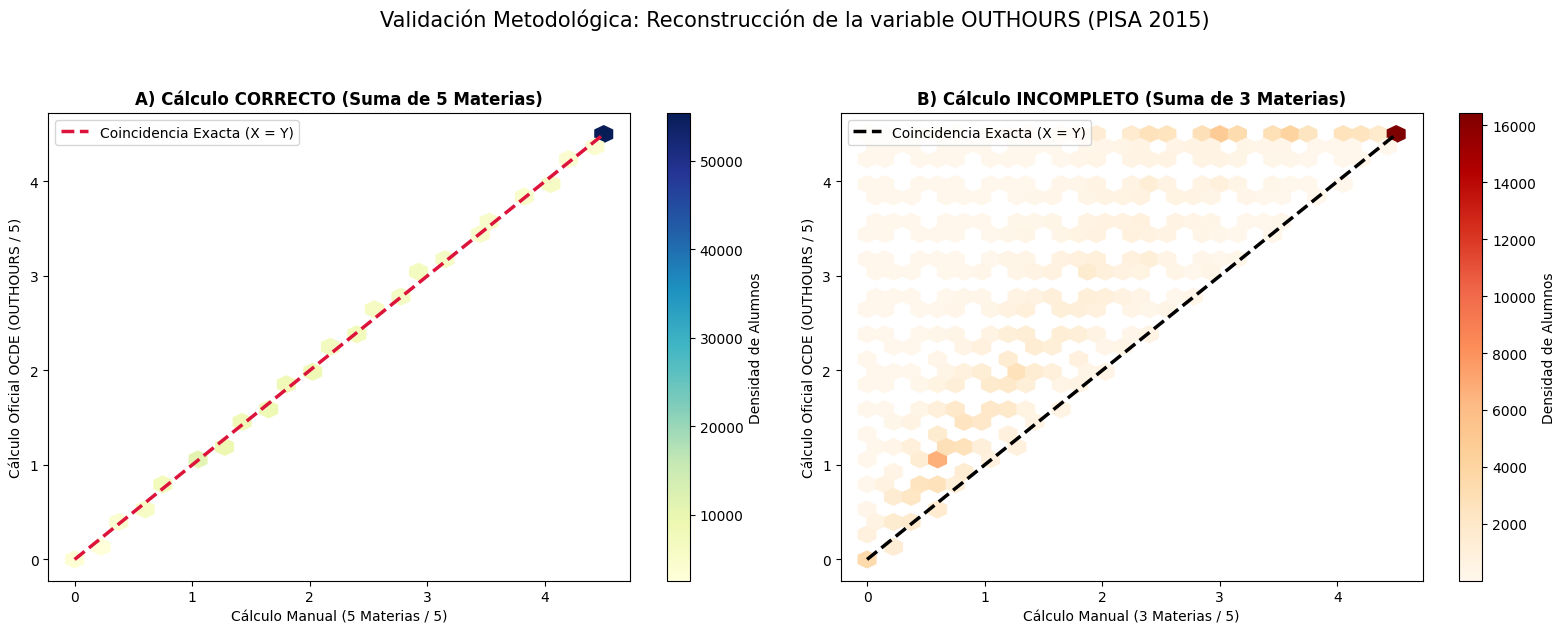

 Correlación con 5 materias: 1.0000 (Ideal es 1.000)
Correlación con 3 materias: 0.8668


In [495]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Comparación con las 5 materias (Debe ser perfecto)
hb1 = axes[0].hexbin(
    x=df_est_2015['manual_5_materias'], 
    y=df_est_2015['outhours_oficial'], 
    gridsize=30, cmap='YlGnBu', mincnt=1  # Paleta Amarillo-Verde-Azul
)
axes[0].plot([0, 4.5], [0, 4.5], color='crimson', linestyle='--', linewidth=2.5, label='Coincidencia Exacta (X = Y)')
cb1 = fig.colorbar(hb1, ax=axes[0])
cb1.set_label('Densidad de Alumnos')
axes[0].set_title('A) Cálculo CORRECTO (Suma de 5 Materias)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Cálculo Manual (5 Materias / 5)')
axes[0].set_ylabel('Cálculo Oficial OCDE (OUTHOURS / 5)')
axes[0].legend()

# Subplot 2: Comparación con solo 3 materias (Quedará desplazado)
hb2 = axes[1].hexbin(
    x=df_est_2015['manual_3_materias'], 
    y=df_est_2015['outhours_oficial'], 
    gridsize=30, cmap='OrRd', mincnt=1  # Paleta Naranja-Rojo
)
axes[1].plot([0, 4.5], [0, 4.5], color='black', linestyle='--', linewidth=2.5, label='Coincidencia Exacta (X = Y)')
cb2 = fig.colorbar(hb2, ax=axes[1])
cb2.set_label('Densidad de Alumnos')
axes[1].set_title('B) Cálculo INCOMPLETO (Suma de 3 Materias)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Cálculo Manual (3 Materias / 5)')
axes[1].set_ylabel('Cálculo Oficial OCDE (OUTHOURS / 5)')
axes[1].legend()

plt.suptitle('Validación Metodológica: Reconstrucción de la variable OUTHOURS (PISA 2015)', fontsize=15, y=1.05)
plt.tight_layout()
plt.show()

# Correlaciones estadísticas de comprobación
corr_5 = df_est_2015['manual_5_materias'].corr(df_est_2015['outhours_oficial'])
corr_3 = df_est_2015['manual_3_materias'].corr(df_est_2015['outhours_oficial'])
print(f" Correlación con 5 materias: {corr_5:.4f} (Ideal es 1.000)")
print(f"Correlación con 3 materias: {corr_3:.4f}")


<div style="background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%); border-left: 5px solid rgba(128, 128, 128, 0.6); padding: 16px; border-radius: 8px; margin: 20px 0;">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    ⚠️ Criterio de Selección suma de indices o OUTHOURS (2012–2022)
  </strong>
    Aunque la suma con OUTHOURS es correcta y oficial, dentro del indice se evaluan más datos sobre deberes que otros cuestionarios PISA para otros añis, esto hace que el numero de horas de deberes para 2015 se dispara en comparación con el resto de ediciones evaluadas (2012,2018 y 2022). Por lo tanto, para que sea equiparable a otros años, nos quedaremos con la suma de los tres indices relativos a las asignaturas trocales de PISA.
</div>


In [496]:
df_est_2015['tiempo_deberes_totales_diarios'] = df_est_2015['manual_3_materias']

df_col_2015['dispone_personal_apoyo'] = df_col_2015['SC052Q02NA'].map(
    {1: 1.0, 2: 0.0, 1.0: 1.0, 2.0: 0.0}
)

df_base_2015_alumno = df_est_2015.merge(
    df_col_2015[claves_colegio + ['dispone_personal_apoyo']],
    on=claves_colegio, how='left', validate='many_to_one'
)

df_base_2015_alumno['year'] = 2015
df_base_2015_alumno = df_base_2015_alumno[columnas_estandar_alumno]

del df_est_2015, df_col_2015
gc.collect()



83940

In [497]:
display(df_base_2015_alumno.head())
display(df_base_2015_alumno.shape)

,CNT,CNTSCHID,CNTSTUID,year,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,dispone_personal_apoyo
0,AUS,3600001,3610676,2015,28.20,0.55,0.80,1.00
1,AUS,3600001,3611874,2015,28.20,0.55,0.80,1.00
2,AUS,3600001,3601769,2015,28.20,0.55,NaN,1.00
3,AUS,3600001,3605996,2015,28.20,0.55,3.40,1.00
4,AUS,3600001,3608147,2015,33.45,0.65,0.60,1.00


(238452, 8)

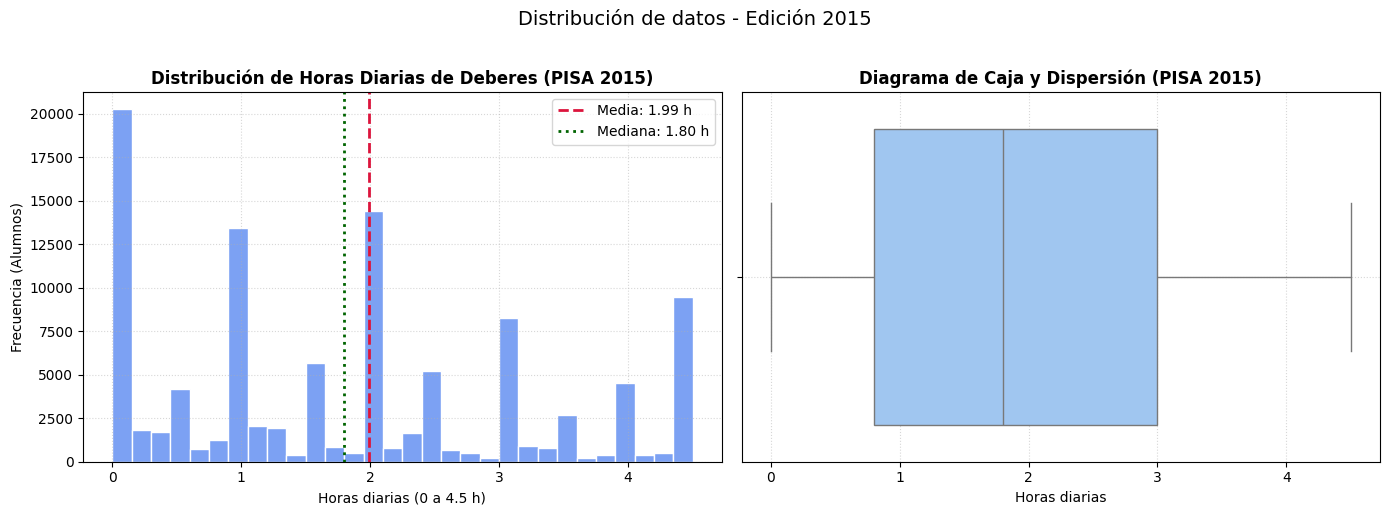

In [498]:
# Extraemos la serie de tiempo limpia excluyendo nulos
serie_2015 = df_base_2015_alumno['tiempo_deberes_totales_diarios'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histograma con curva de densidad (KDE)
sns.histplot(
    serie_2018,
    kde=False,
    bins=30,
    color='#2563eb',
    edgecolor='white',
    alpha=0.6,
    ax=axes[0]
)
media_val = serie_2015.mean()
mediana_val = serie_2015.median()

axes[0].axvline(media_val, color='crimson', linestyle='--', linewidth=2, label=f'Media: {media_val:.2f} h')
axes[0].axvline(mediana_val, color='darkgreen', linestyle=':', linewidth=2, label=f'Mediana: {mediana_val:.2f} h')
axes[0].set_title('Distribución de Horas Diarias de Deberes (PISA 2015)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Horas diarias (0 a 4.5 h)')
axes[0].set_ylabel('Frecuencia (Alumnos)')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.5)

# 2. Boxplot (Diagrama de caja para cuartiles y dispersión)
sns.boxplot(
    x=serie_2015,
    color='#93c5fd',
    ax=axes[1],
    fliersize=3
)
axes[1].set_title('Diagrama de Caja y Dispersión (PISA 2015)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Horas diarias')
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Distribución de datos - Edición 2015', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [499]:
df_base_2015_alumno['tiempo_deberes_totales_diarios'].describe()

count   212951.00
mean         1.99
std          1.36
min          0.00
25%          0.80
50%          1.80
75%          3.00
max          4.50
Name: tiempo_deberes_totales_diarios, dtype: float64

In [501]:
#TODO Esto cambia y generar pequeña explicacion

* El hecho de que el **percentil 75 (75%) sea 4,50** indica que más del **25% de los alumnos** en PISA 2015 tenían valores calculados de `OUTHOURS / 5` superiores o iguales a 4,5 horas diarias

* El valor `4,5` ya no representa exactamente "4 horas y media fijas", sino la categoría **"4,5 horas o más al día"** (*top-coded category*)
* Ese pico representa a los estudiantes de **alta dedicación o sobrecarga de trabajo autónomo** [PISA 2015 VOL II.pdf, PISA 2022 Results vol II.pdf]. Eliminar a ese 25% de la muestra sesgaría gravemente tu estudio, ya que eliminarías precisamente a los alumnos que más horas estudian en toda la muestra de la OCDE

# Obtención de datos equivalentes PISA 2018

### Construcción del equivalente Tiempo Total de Deberes en PISA 2018

En PISA 2018, la información sobre el tiempo de estudio en casa se extrae del Cuestionario de Trayectoria Educativa (*Educational Career*). Se evalúa el tiempo dedicado en un día escolar típico utilizando exclusivamente las variables de horas (omitiendo los minutos para simplificar la transformación):

* **`EC158Q01HA`**: Horas de estudio antes de ir al colegio.
* **`EC159Q01HA`**: Horas de estudio después de volver del colegio.

**Regla de codificación:**
Dado que las preguntas se refieren directamente a un "día escolar típico", el cálculo final no requiere promediarse entre 5 días. Las variables originales son categóricas y se transforman siguiendo esta lógica:

1. **Limpieza y conversión**: Se excluyen los códigos de control (valores $\ge 10$) y se resta 1 a la categoría para obtener la hora real (valor 1 = 0h, 2 = 1h).
2. **Suma y armonización**: Se suman los bloques de mañana y tarde. Para mantener la coherencia de escala con los ciclos 2012 y 2022, se aplica un límite de contención (*clipping*) estableciendo un máximo de **4.5** horas.

$$tiempo\_deberes\_totales\_diarios = horas\_antes + horas\_despues$$

In [ ]:
#TODO REVISAR DATOS y justificar porque se quita antes de colegio : porque segun la OCDE es antes de de hacer el examen PISA

In [ ]:
ruta_est_2018 = RUTA_DATOS_ANUALES / 'pisa2018_estudiantes.parquet'
ruta_col_2018 = RUTA_DATOS_ANUALES / 'pisa2018_colegios.parquet'
pv1_2018 = obtener_primer_pv_math(ruta_est_2018)

cols_est_2018 = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + ['EC158Q01HA', 'EC158Q02HA','EC159Q01HA','EC159Q02HA']
))
df_est_2018 = pd.read_parquet(ruta_est_2018, columns=cols_est_2018).rename(columns={pv1_2018: 'PV1MATH'})
df_col_2018 = pd.read_parquet(
    ruta_col_2018, columns=claves_colegio + ['SC052Q02NA']
).drop_duplicates(subset=claves_colegio)

In [473]:
def limpiar_horas_ec(serie_horas):
    """
    Limpia la escala desplazada de horas de PISA 2018 (ECQ).
    1 a 9 -> restar 1 para obtener horas reales (0h a 8h).
    11 -> 0.0 horas ("No estudié").
    10 ("No recuerdo") y códigos >= 95 (Valid Skip, Missing, etc.) -> NaN.
    """
    condiciones = [
        serie_horas.between(1, 9),
        serie_horas == 11
    ]
    valores = [
        serie_horas - 1,
        0.0
    ]
    # np.select devuelve un numpy.ndarray. 
    # Lo envolvemos en pd.Series para conservar el índice original y poder usar .add()
    resultado = np.select(condiciones, valores, default=np.nan)
    return pd.Series(resultado, index=serie_horas.index)

def limpiar_minutos_ec(serie_minutos):
    """
    Limpia la escala desplazada de minutos de PISA 2018 (ECQ).
    1 a 12 -> convertimos a minutos reales: (valor - 1) * 5
    14 -> 0.0 minutos ("No estudié").
    13 ("No recuerdo") y códigos >= 95 (Valid Skip, Missing, etc.) -> NaN.
    """
    condiciones = [
        serie_minutos.between(1, 12),
        serie_minutos == 14
    ]
    valores = [
        (serie_minutos - 1) * 5.0,  
        0.0
    ]
    resultado = np.select(condiciones, valores, default=np.nan)
    return pd.Series(resultado, index=serie_minutos.index)


# # --- Bloque Mañana (Antes del colegio) ---
# h_manana = limpiar_horas_ec(df_est_2018['EC158Q01HA'])
# m_manana = limpiar_minutos_ec(df_est_2018['EC158Q02HA']) / 60.0

# Usamos .add(fill_value=0) por si el alumno rellenó las horas pero dejó los minutos en blanco (y viceversa)
# t_manana = h_manana.add(m_manana, fill_value=0)


# --- Bloque Tarde (Después del colegio) ---
h_tarde = limpiar_horas_ec(df_est_2018['EC159Q01HA'])
m_tarde = limpiar_minutos_ec(df_est_2018['EC159Q02HA']) / 60.0

t_tarde = h_tarde.add(m_tarde, fill_value=0)


# --- Suma horizontal y acotación superior ---
df_est_2018['tiempo_deberes_totales_diarios'] = (
    # pd.concat([t_manana, t_tarde], axis=1)
    pd.concat([t_tarde], axis=1)
    .sum(axis=1, min_count=1)
    .clip(upper=4.5)  # Solo limitamos por arriba para no falsear los "0" reales por abajo
)

In [474]:
df_est_2018['tiempo_deberes_totales_diarios'].agg(['min','max'])

min   0.00
max   4.50
Name: tiempo_deberes_totales_diarios, dtype: float64

In [475]:
#Mapeamos la variable binaria para personal de Apoyo
df_col_2018['dispone_personal_apoyo'] = df_col_2018['SC052Q02NA'].map({1: 1.0, 2: 0.0, 1.0: 1.0, 2.0: 0.0})

In [476]:
df_base_2018_alumno = df_est_2018.merge(
    df_col_2018[claves_colegio + ['dispone_personal_apoyo']],
    on=claves_colegio, how='left', validate='many_to_one'
)
df_base_2018_alumno['year'] = 2018
df_base_2018_alumno = df_base_2018_alumno[columnas_estandar_alumno]

del df_est_2018, df_col_2018
gc.collect()

7832

In [502]:
display(df_base_2018_alumno.head())
display(df_base_2018_alumno.shape)

NameError: name 'df_base_2018_alumno' is not defined

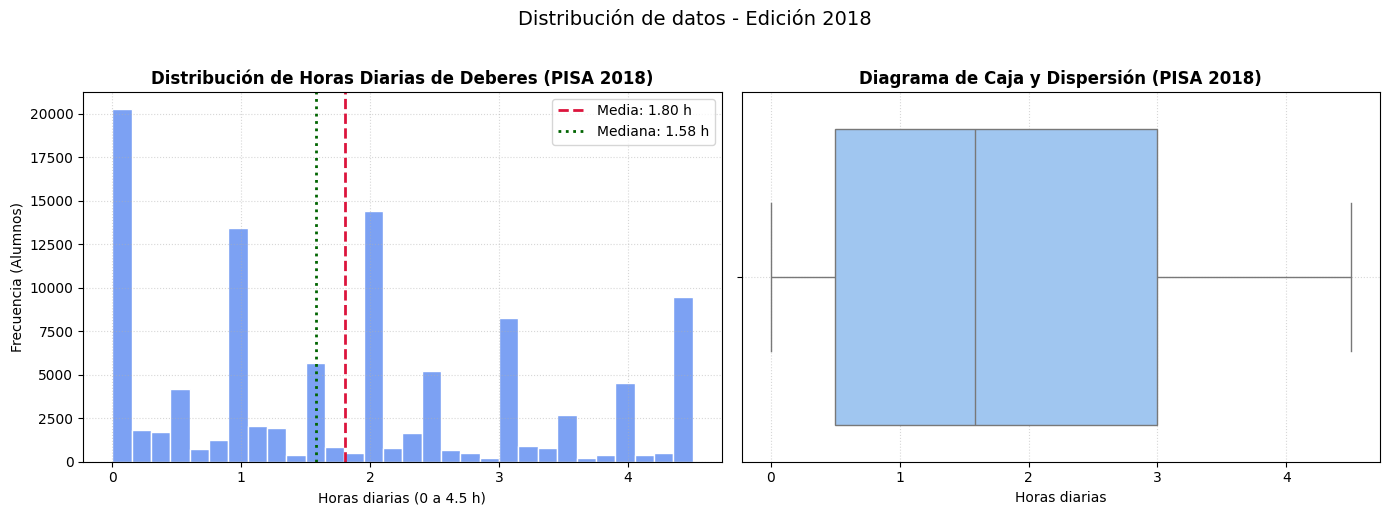

In [478]:
# Extraemos la serie de tiempo limpia excluyendo nulos
serie_2018 = df_base_2018_alumno['tiempo_deberes_totales_diarios'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histograma con curva de densidad (KDE)
sns.histplot(
    serie_2018,
    kde=False,
    bins=30,
    color='#2563eb',
    edgecolor='white',
    alpha=0.6,
    ax=axes[0]
)
media_val = serie_2018.mean()
mediana_val = serie_2018.median()

axes[0].axvline(media_val, color='crimson', linestyle='--', linewidth=2, label=f'Media: {media_val:.2f} h')
axes[0].axvline(mediana_val, color='darkgreen', linestyle=':', linewidth=2, label=f'Mediana: {mediana_val:.2f} h')
axes[0].set_title('Distribución de Horas Diarias de Deberes (PISA 2018)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Horas diarias (0 a 4.5 h)')
axes[0].set_ylabel('Frecuencia (Alumnos)')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.5)

# 2. Boxplot (Diagrama de caja para cuartiles y dispersión)
sns.boxplot(
    x=serie_2018,
    color='#93c5fd',
    ax=axes[1],
    fliersize=3
)
axes[1].set_title('Diagrama de Caja y Dispersión (PISA 2018)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Horas diarias')
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Distribución de datos - Edición 2018', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Concatenacion Y Almacenamiento de Datos Esfuerzo en PISA (2012-2022)

In [479]:
df_esfuerzo_panel_alumno = pd.concat(
    [df_base_2012_alumno, df_base_2015_alumno, df_base_2018_alumno, df_base_2022_alumno],
    ignore_index=True
)

# Liberamos los DataFrames anuales individuales
del df_base_2012_alumno, df_base_2015_alumno, df_base_2018_alumno, df_base_2022_alumno
gc.collect()

# Generamos la vista a nivel PAÍS en memoria (exclusivamente para los gráficos longitudinales del EDA)
df_medias_pais_historico = pd.read_parquet(
    RUTA_ASIGNATURAS / 'pisa_medias_asignaturas_pais_anual.parquet',
    columns=['CNT', 'year', 'media_math_pais']
)

df_indicadores_pais_historico = promedio_ponderado_indicadores_agrupado(
    df_esfuerzo_panel_alumno,
    ['tiempo_deberes_totales_diarios', 'dispone_personal_apoyo'],
    'W_FSTUWT',
    ['CNT', 'year']
)

df_deberes_panel_pais = df_medias_pais_historico.merge(
    df_indicadores_pais_historico, on=['CNT', 'year'], how='inner', validate='one_to_one'
)

print(f"✅ Panel longitudinal a nivel ALUMNO: {len(df_esfuerzo_panel_alumno):,} filas")

display(df_esfuerzo_panel_alumno.head())

✅ Panel longitudinal a nivel ALUMNO: 1,066,807 filas


,CNT,CNTSCHID,CNTSTUID,year,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,dispone_personal_apoyo
0,AUS,0000001,00001,2012,33.39,0.67,1.20,1.00
1,AUS,0000001,00002,2012,33.39,0.67,1.00,1.00
2,AUS,0000001,00003,2012,33.39,0.67,4.50,1.00
3,AUS,0000001,00004,2012,35.22,0.70,1.80,1.00
4,AUS,0000001,00005,2012,35.22,0.70,2.20,1.00


In [480]:
# Guardado únicamente a nivel COLEGIO y PAÍS
df_esfuerzo_panel_alumno.to_parquet(RUTA_INTERMEDIOS / 'pisa_esfuerzo_alumno_anual.parquet', index=False)
print(" Archivos exportados correctamente a nivel Alumno y País.")

 Archivos exportados correctamente a nivel Alumno y País.


# Auditoría final de Datos en Conjunto y Datos Faltantes (*Missingness*) por Edición (2012–2022)

Dado que la OCDE modifica el diseño de los cuestionarios de contexto en cada ciclo de PISA, los índices armonizados (`tiempo_deberes_totales_diarios` y `dispone_personal_apoyo`) se han construido a partir de aproximaciones equivalentes (*crosswalk*). Esto genera **ausencias estructurales** desiguales entre ediciones:

* **PISA 2012:** Menor cobertura de países en el bloque de tiempo de estudio (`ST57`) y uso de variables *proxy* para el apoyo escolar.

* **PISA 2015 y 2018:** Incorporación progresiva del bloque de apoyo escolar (`SC052`) y diferencias de cobertura en los bloques de horas de estudio (`ST071` / `ST160` / módulo opcional `EC`).

* **PISA 2022:** Cobertura casi completa en los ítems centrales (`ST296Q04JA` y `SC212Q02JA`).

A continuación, se cuantifica el volumen de datos válidos y el porcentaje de `NaN` por edición para dejar documentada esta limitación metodológica antes del modelado.

Datos Faltantes (Missingness) por Edición PISA (2012-2022):


,year,Colegios_Totales,Paises_Totales,Colegios_con_Deberes,NaN_Deberes_Colegio_pct,Colegios_con_Apoyo,NaN_Apoyo_Colegio_pct,NaN_Deberes_Pais_pct,NaN_Apoyo_Pais_pct
0,2012,290158,33,186573,35.70,279104,3.81,0.00,0.00
1,2015,238452,33,212951,10.69,216328,9.28,0.00,0.00
2,2018,269587,33,106221,60.60,247437,8.22,54.55,3.03
3,2022,268610,33,242183,9.84,241146,10.22,0.00,0.00


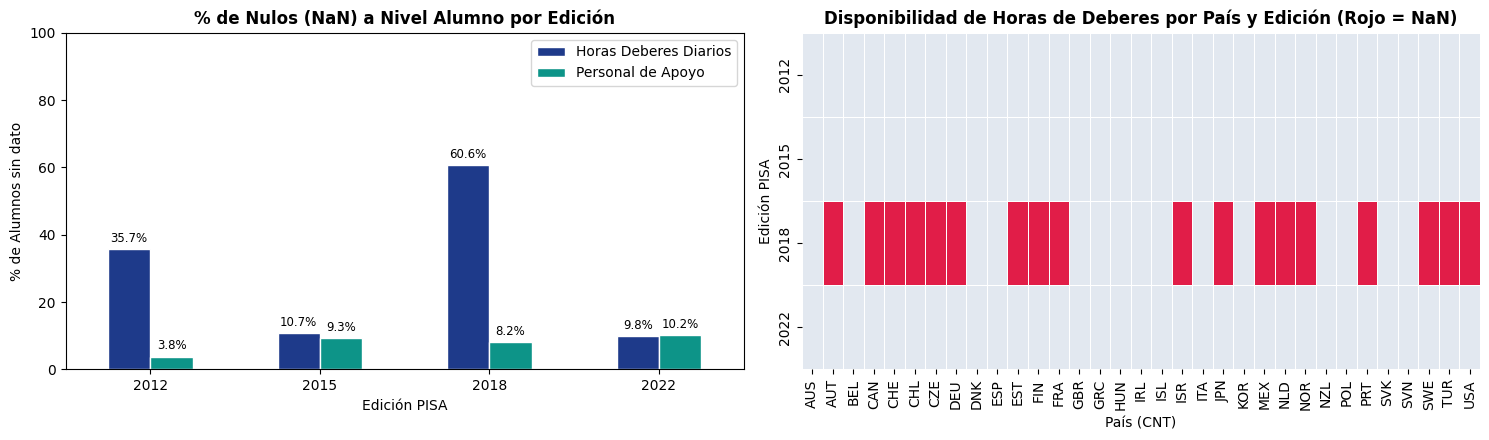

In [481]:
# ANÁLISIS SIMPLE DE MISSINGNESS (NaN) POR EDICIÓN
resumen_nulos_edicion = (
    df_esfuerzo_panel_alumno.groupby('year')
    .agg(
        Colegios_Totales=('CNTSCHID', 'count'),
        Paises_Totales=('CNT', 'nunique'),
        Colegios_con_Deberes=('tiempo_deberes_totales_diarios', 'count'),
        NaN_Deberes_Colegio_pct=('tiempo_deberes_totales_diarios', lambda s: (s.isna().mean() * 100).round(2)),
        Colegios_con_Apoyo=('dispone_personal_apoyo', 'count'),
        NaN_Apoyo_Colegio_pct=('dispone_personal_apoyo', lambda s: (s.isna().mean() * 100).round(2))
    )
    .reset_index()
)

# Añadimos % de Países enteros con NaN en cada edición (usando el panel de países)
nan_pais_edicion = (
    df_deberes_panel_pais.groupby('year')
    .agg(
        NaN_Deberes_Pais_pct=('tiempo_deberes_totales_diarios', lambda s: (s.isna().mean() * 100).round(2)),
        NaN_Apoyo_Pais_pct=('dispone_personal_apoyo', lambda s: (s.isna().mean() * 100).round(2))
    )
    .reset_index()
)
resumen_nulos_edicion = resumen_nulos_edicion.merge(nan_pais_edicion, on='year')

print("Datos Faltantes (Missingness) por Edición PISA (2012-2022):")
display(resumen_nulos_edicion)

# Visualización rápida de Missingness por Edición (Colegios vs. Países)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

resumen_nulos_edicion.set_index('year')[['NaN_Deberes_Colegio_pct', 'NaN_Apoyo_Colegio_pct']].plot(
    kind='bar', ax=axes[0], color=['#1e3a8a', '#0d9488'], edgecolor='white', rot=0
)
axes[0].set_title('% de Nulos (NaN) a Nivel Alumno por Edición', fontweight='bold')
axes[0].set_ylabel('% de Alumnos sin dato')
axes[0].set_xlabel('Edición PISA')
axes[0].set_ylim(0, 100)
axes[0].legend(['Horas Deberes Diarios', 'Personal de Apoyo'])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1f%%', padding=3, fontsize=8.5)

# Pivot table de País x Año para ver qué países faltan en cada edición
pivot_missing_pais = df_deberes_panel_pais.pivot(
    index='year', columns='CNT', values='tiempo_deberes_totales_diarios'
).isna()

sns.heatmap(
    pivot_missing_pais, cmap=['#e2e8f0', '#e11d48'], cbar=False,
    linewidths=0.5, linecolor='white', ax=axes[1]
)
axes[1].set_title('Disponibilidad de Horas de Deberes por País y Edición (Rojo = NaN)', fontweight='bold')
axes[1].set_xlabel('País (CNT)')
axes[1].set_ylabel('Edición PISA')

plt.tight_layout()
plt.show()



In [490]:
#TODO Explicacion

Resumen de la distribución de los datos de Deberes y Apoyo (Nivel Alumno):


tiempo_deberes_totales_diarios                             \
                              count mean  std  min median  max   
year                                                             
2012                         186573 1.43 1.17 0.00   1.00 4.50   
2015                         212951 1.99 1.36 0.00   1.80 4.50   
2018                         106221 1.80 1.44 0.00   1.58 4.50   
2022                         242183 1.50 1.22 0.25   1.50 4.50   

     dispone_personal_apoyo                             
                      count mean  std  min median  max  
year                                                    
2012                 279104 0.57 0.50 0.00   1.00 1.00  
2015                 216328 0.61 0.49 0.00   1.00 1.00  
2018                 247437 0.61 0.49 0.00   1.00 1.00  
2022                 241146 0.63 0.48 0.00   1.00 1.00

C:\Users\victo\AppData\Local\Temp\ipykernel_37272\1199644380.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\victo\AppData\Local\Temp\ipykernel_37272\1199644380.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


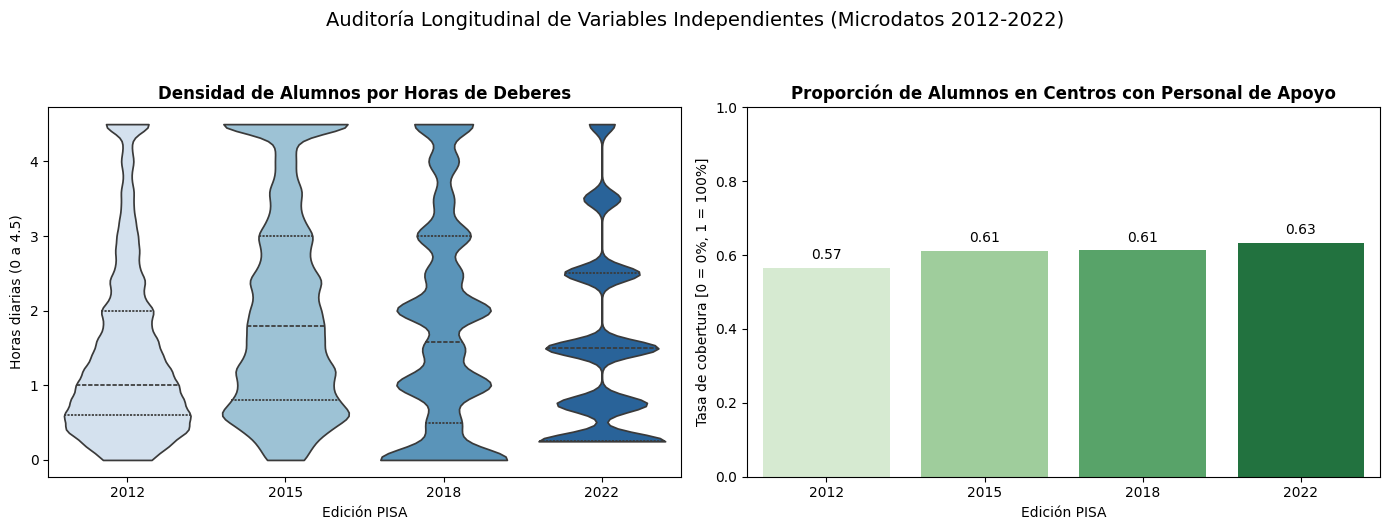

In [483]:

#Resumen de la tabla final 
print("Resumen de la distribución de los datos de Deberes y Apoyo (Nivel Alumno):")

# Evaluamos solo las variables que tienes en este DataFrame
columnas_auditoria = ['tiempo_deberes_totales_diarios', 'dispone_personal_apoyo']

resumen_panel = (
    df_esfuerzo_panel_alumno.groupby('year')[columnas_auditoria]
    .agg(['count', 'mean', 'std', 'min', 'median', 'max'])
    .round(2)
)
display(resumen_panel)

#Visualización de la distribución de los deberes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A) Variable de Esfuerzo: Horas Totales de Deberes
# Usamos Violinplot para ver dónde se concentra la masa de cientos de miles de alumnos
sns.violinplot(
    data=df_esfuerzo_panel_alumno, 
    x='year', 
    y='tiempo_deberes_totales_diarios', 
    palette='Blues', 
    inner='quartile',
    cut=0, # Evita que el violín dibuje estimaciones por debajo de 0 o encima de 4.5
    ax=axes[0]
)
axes[0].set_title('Densidad de Alumnos por Horas de Deberes', fontweight='bold')
axes[0].set_xlabel('Edición PISA')
axes[0].set_ylabel('Horas diarias (0 a 4.5)')

# B) Variable de Soporte: Proporción de Personal de Apoyo
# Un barplot sobre una variable 0/1 muestra directamente el porcentaje de cobertura (la media)
sns.barplot(
    data=df_esfuerzo_panel_alumno, 
    x='year', 
    y='dispone_personal_apoyo', 
    palette='Greens', 
    errorbar=None, # Quitamos la barra de error para una lectura más limpia
    ax=axes[1]
)
axes[1].set_title('Proporción de Alumnos en Centros con Personal de Apoyo', fontweight='bold')
axes[1].set_xlabel('Edición PISA')
axes[1].set_ylabel('Tasa de cobertura [0 = 0%, 1 = 100%]')
axes[1].set_ylim(0, 1)

# Añadimos las etiquetas de porcentaje encima de las barras para facilitar la lectura
for p in axes[1].patches:
    axes[1].annotate(format(p.get_height(), '.2f'), 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha = 'center', va = 'center', 
                     xytext = (0, 9), 
                     textcoords = 'offset points')

plt.suptitle('Auditoría Longitudinal de Variables Independientes (Microdatos 2012-2022)', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

In [491]:
#TODO Conclusiones